# Cuatro noches de noviembre en Cheté

Juan Montoya y Laura Ostos


## 1. Nuestra estimación antes de ver las capturas

Propusimos cuatro recipientes pasivos por noche, durante cuatro noches de noviembre en Cheté: dos en población y dos cerca de una mina. Funcionarían 8–10 horas mientras las personas duermen. Los recipientes 1 y 2 serían oscuros; 3 y 4, claros.

Supusimos 200 ± 50 individuos por recipiente y noche. El producto literal es 3200 ± 800; en la [primera entrega](../EstimacionFermi_00/estimacion_inicial.md) redondeamos el centro a 3000. El margen representa escenarios imaginados, no un intervalo de confianza. El supuesto por comprobar es cuánto captura un recipiente.

In [1]:
from pathlib import Path
from zipfile import ZipFile
from xml.etree import ElementTree
from hashlib import sha256
import importlib.metadata as versiones
import json
import math
import re
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats
from matplotlib.path import Path as Trayectoria
from matplotlib.patches import PathPatch, Rectangle
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import PoissonRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

semilla = 829
set_matplotlib_formats("retina")
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 11})
pd.set_option("display.max_columns", 12)
pd.set_option("display.precision", 2)

nombreArchivo = "dwca-ins_mosquiteros_malaria-v1.0.zip"
sintesis = Path.cwd()
if not (sintesis / "Datos" / nombreArchivo).is_file():
    sintesis /= "SintesisFinal_02"
datos = sintesis / "Datos"
archivo = datos / nombreArchivo
if not archivo.is_file():
    raise FileNotFoundError("Abra el notebook desde la carpeta del equipo o SintesisFinal_02.")
huella = sha256(archivo.read_bytes()).hexdigest()
print("Huella del archivo:", huella)
print("Versiones:", {p: versiones.version(p) for p in
                    ["numpy", "pandas", "matplotlib", "scikit-learn"]})

Huella del archivo: 7ab6376eb3a8279b4f634507c97d7a820027688cbb9e7b24f4c6e97a0f02ed34
Versiones: {'numpy': '2.3.5', 'pandas': '2.3.3', 'matplotlib': '3.10.9', 'scikit-learn': '1.8.0'}


In [2]:
nochesFermi = 4
recipientes = 4
porRecipiente = 200
margenRecipiente = 50
fermiOriginal = 3000
margenOriginal = 800
horasSueno = np.array([8, 10])
mesPropuesto = 11
fermiProducto = nochesFermi * recipientes * porRecipiente
margenProducto = nochesFermi * recipientes * margenRecipiente

fermiPorNoche = recipientes * porRecipiente
print(f"{porRecipiente} × {recipientes} = {fermiPorNoche} por noche; "
      f"× {nochesFermi} noches = {fermiProducto} ({fermiProducto-margenProducto}–{fermiProducto+margenProducto}).")

200 × 4 = 800 por noche; × 4 noches = 3200 (2400–4000).


## 2. Fermi frente a las 285 noches del estudio

El estudio hizo captura activa con dos colectores por vivienda, habitualmente durante doce horas (catorce en la línea base). Su resumen reúne las noches de Guapi, Timbiquí y Santa Bárbara. Podemos comparar el orden de magnitud regional antes de preguntar cuánto cambia al filtrar Cheté. Las noches del resumen no son noches de un solo punto ni horas de recipiente.

In [3]:
with ZipFile(archivo) as comprimido:
    metadatos = ElementTree.fromstring(comprimido.read("eml.xml"))
resumenEML = " ".join(" ".join(metadatos.itertext()).split())

def enteroDelResumen(patron):
    hallazgo = re.search(patron, resumenEML, flags=re.IGNORECASE)
    if not hallazgo:
        raise ValueError(f"No se encontró esta cifra en eml.xml: {patron}")
    return int(hallazgo.group(1).replace(".", ""))

nochesResumen = enteroDelResumen(r"durante ([\d.]+) noches en los municipios")
localidadesResumen = enteroDelResumen(r"domicilio humano en ([\d.]+) localidades")
registrosResumen = enteroDelResumen(r"([\d.]+) registros biológicos")
individuosResumen = enteroDelResumen(r"representados en ([\d.]+) mosquitos")
fermiExtendida = fermiPorNoche * nochesResumen
deltaFermi = fermiExtendida - individuosResumen
porcentajeFermi = 100 * deltaFermi / individuosResumen
promedioPublicado = individuosResumen / nochesResumen

def enteroES(n):
    return f"{n:,.0f}".replace(",", " ")

print(f"Fermi literal: {porRecipiente} × {recipientes} × {nochesResumen} = {enteroES(fermiExtendida)}.")
print(f"Estudio: {enteroES(individuosResumen)} individuos en {enteroES(registrosResumen)} registros; "
      f"{promedioPublicado:.1f} por noche de campaña frente a los {fermiPorNoche} imaginados.")
print(f"Diferencia: {enteroES(abs(deltaFermi))} menos, {abs(porcentajeFermi):.2f} % del total publicado.")
print(f"En la otra dirección: {nochesFermi} × {promedioPublicado:.1f} ≈ "
      f"{enteroES(nochesFermi * promedioPublicado)} por cuatro noches regionales, frente a "
      f"{enteroES(fermiProducto)} en la cuenta literal.")

Fermi literal: 200 × 4 × 285 = 228 000.
Estudio: 229 394 individuos en 1 502 registros; 804.9 por noche de campaña frente a los 800 imaginados.
Diferencia: 1 394 menos, 0.61 % del total publicado.
En la otra dirección: 4 × 804.9 ≈ 3 220 por cuatro noches regionales, frente a 3 200 en la cuenta literal.


Así, el supuesto literal sí estuvo cerca del total regional. Si escaláramos los 3000 ya redondeados, partiríamos de 750 por noche, no de 800. La cercanía entre totales no demuestra que cada recipiente capture 200: el estudio usó otro método y reunió muchas localidades.

## 3. Observación y reserva

Una fila del ZIP reúne individuos de una especie en un evento. Unimos los puntos de una localidad en un mes para formar una visita. En Cheté reservamos las visitas 20–22 (enero–marzo de 2023) antes del análisis original de Poisson. Para los bosques conservamos el corte, aunque su evaluación es retrospectiva porque ya conocíamos la reserva.

In [4]:
columnasCalendario = ["eventID", "parentEventID", "county", "locality", "eventDate",
                     "eventTime", "samplingEffort"]
with ZipFile(archivo) as comprimido:
    with comprimido.open("occurrence.txt") as tabla:
        calendario = pd.read_csv(tabla, sep="\t", usecols=columnasCalendario,
                                dtype="string")

calendarioChete = calendario.loc[calendario.locality.eq("Cheté")].copy()
calendarioChete["visita"] = calendarioChete.eventID.str.extract(
    r"^Chete[12]-(\d+)$", expand=False
).astype(int)
assert set(calendarioChete.visita) == set(range(1, 23))

reserva = pd.DataFrame([
    ("Chete1-20", "2023-01"), ("Chete2-20", "2023-01"),
    ("Chete1-21", "2023-02"), ("Chete2-21", "2023-02"),
    ("Chete1-22", "2023-03"), ("Chete2-22", "2023-03"),
], columns=["eventID", "periodo"])
eventosReserva = set(reserva.eventID)
assert eventosReserva == {f"Chete{p}-{v}" for p in (1, 2) for v in (20, 21, 22)}
filasDesarrollo = set(calendarioChete.index[calendarioChete.visita.le(19)])
filasReserva = set(calendarioChete.index[calendarioChete.eventID.isin(eventosReserva)])
assert filasDesarrollo.isdisjoint(filasReserva)
assert len(filasDesarrollo | filasReserva) == len(calendarioChete)

def leerFilas(indices):
    # La fila 0 del archivo es el encabezado.
    with ZipFile(archivo) as comprimido:
        with comprimido.open("occurrence.txt") as tabla:
            return pd.read_csv(
                tabla, sep="\t", dtype="string",
                skiprows=lambda fila: fila > 0 and fila - 1 not in indices
            )

desarrollo = leerFilas(filasDesarrollo)
assert not desarrollo.eventID.isin(eventosReserva).any()
print("Por ahora solo abrimos las", len(desarrollo), "filas de desarrollo.")

Por ahora solo abrimos las 67 filas de desarrollo.


## 4. Conteos a igual esfuerzo

Sumamos `individualCount`. En un punto no sumamos las noches repetidas entre especies: tomamos el máximo declarado. El esfuerzo aproximado es \(E=2\times\text{horas por noche}\times\text{noches}\). En cada grupo, la tasa es \(\sum Y/\sum E\); multiplicarla por **96 horas de colector** representa una pareja trabajando cuatro noches de doce horas en total.

Una fila ausente no es un cero. Recuperamos una fecha de captura solo si otras filas del evento coinciden. Las fechas de laboratorio no ordenan visitas. Las comprobaciones siguientes dejan visibles los problemas.

In [5]:
def preparar(datos):
    d = datos.copy()
    d["visita"] = d.eventID.str.extract(r"^Chete[12]-(\d+)$", expand=False).astype(int)
    d["conteo"] = pd.to_numeric(d.individualCount, errors="coerce")
    esfuerzo = d.samplingEffort.str.extract(r"^(\d+) h por noche, (\d+) noches?$")
    d["horas"] = pd.to_numeric(esfuerzo[0], errors="coerce")
    d["noches"] = pd.to_numeric(esfuerzo[1], errors="coerce")
    faltaban = d.eventDate.isna()
    for evento, grupo in d.groupby("eventID"):
        conocidas = grupo.eventDate.dropna().unique()
        if len(conocidas) == 1:
            d.loc[grupo.index, "eventDate"] = grupo.eventDate.fillna(conocidas[0])
    fechas = d.eventDate.str.split("/")
    d["inicio"] = pd.to_datetime(fechas.str[0], errors="coerce")
    d["fin"] = pd.to_datetime(fechas.str[-1], errors="coerce")
    d["fechaRecuperada"] = faltaban & d.eventDate.notna()

    assert d.id.is_unique and d.occurrenceID.is_unique
    d["claveRepetida"] = d.duplicated(["eventID", "scientificName"], keep=False)
    assert d.conteo.notna().all() and d.conteo.ge(0).all()
    assert d.conteo.mod(1).eq(0).all()
    assert d[["horas", "noches"]].notna().all().all()
    assert d.horas.gt(0).all() and d.noches.gt(0).all()
    assert d[["inicio", "fin"]].notna().all().all()
    assert d.fin.ge(d.inicio).all()
    assert d.scientificName.str.startswith("Anopheles ").all()
    assert d.samplingProtocol.eq("Aspirador bucal | Colecta con cebo humano").all()
    return d

d = preparar(desarrollo)
fechasLab = d.dateIdentified.str.split("/")
inicioLab = pd.to_datetime(fechasLab.str[0], errors="coerce")
finLab = pd.to_datetime(fechasLab.str[-1], errors="coerce")
problemaLab = inicioLab.isna() | finLab.isna() | finLab.lt(inicioLab)

nochesDistintas = d.groupby("eventID").noches.nunique().gt(1)
print(f"{d.occurrenceID.nunique()} registros, {d.eventID.nunique()} eventos y "
      f"{d.conteo.sum():.0f} individuos en desarrollo. {nochesDistintas.sum()} eventos "
      f"declaran distintas noches entre especies.")
print("Fechas de laboratorio problemáticas en:", ", ".join(d.loc[problemaLab, "eventID"].unique()))

67 registros, 38 eventos y 6540 individuos en desarrollo. 2 eventos declaran distintas noches entre especies.
Fechas de laboratorio problemáticas en: Chete1-10, Chete2-10


In [6]:
esfuerzoObjetivo = 4 * 12 * 2

def agruparVisitas(datos):
    assert datos.groupby("eventID").horas.nunique().eq(1).all()
    puntos = datos.groupby(["visita", "parentEventID"], as_index=False).agg(
        conteo=("conteo", "sum"), horas=("horas", "first"),
        noches=("noches", "max"), inicio=("inicio", "min"), fin=("fin", "max")
    )
    puntos["esfuerzo"] = 2 * puntos.horas * puntos.noches
    puntos["tasa"] = puntos.conteo / puntos.esfuerzo
    puntos["cuatroNoches"] = esfuerzoObjetivo * puntos.tasa
    visitas = puntos.groupby("visita", as_index=False).agg(
        conteo=("conteo", "sum"), esfuerzo=("esfuerzo", "sum"),
        inicio=("inicio", "min"), fin=("fin", "max"),
        puntos=("parentEventID", "nunique")
    ).sort_values("visita").reset_index(drop=True)
    assert visitas.puntos.eq(2).all()
    assert visitas.inicio.is_monotonic_increasing
    assert (visitas.fin.iloc[:-1].to_numpy() < visitas.inicio.iloc[1:].to_numpy()).all()
    visitas["fecha"] = visitas.inicio.dt.to_period("M").dt.to_timestamp()
    visitas["tasa"] = visitas.conteo / visitas.esfuerzo
    visitas["cuatroNoches"] = esfuerzoObjetivo * visitas.tasa
    assert int(visitas.conteo.sum()) == int(datos.conteo.sum())
    return puntos, visitas

puntos, visitas = agruparVisitas(d)
print(f"{len(visitas)} visitas de desarrollo y {len(puntos)} eventos de punto en Cheté.")

ejemplo = visitas.loc[visitas.visita.eq(3)].iloc[0]
print(f"Ejemplo de la visita 3: {ejemplo.conteo:.0f} individuos / "
      f"{ejemplo.esfuerzo:.0f} horas de colector × {esfuerzoObjetivo} "
      f"= {ejemplo.cuatroNoches:.0f} mosquitos equivalentes.")

19 visitas de desarrollo y 38 eventos de punto en Cheté.
Ejemplo de la visita 3: 333 individuos / 144 horas de colector × 96 = 222 mosquitos equivalentes.


### Distribución de las capturas locales

Cada histograma cuenta eventos. El segundo corrige por esfuerzo: dos eventos con el mismo conteo no necesariamente tuvieron el mismo rendimiento.

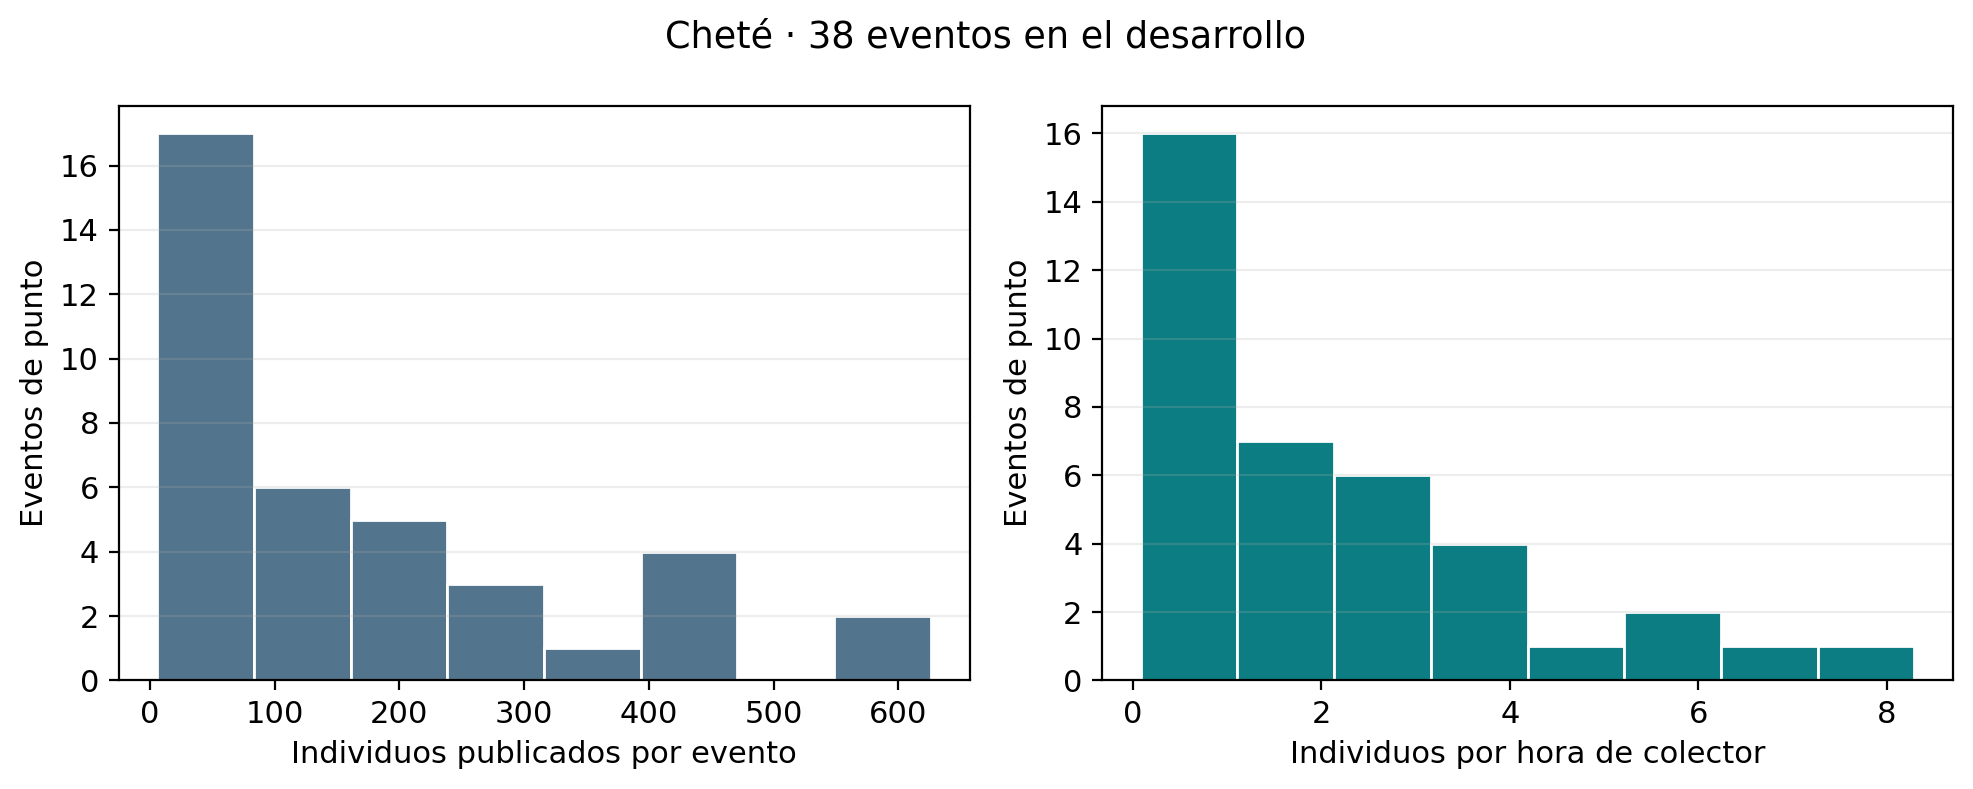

In [7]:
figuraLocal, ejes = plt.subplots(1, 2, figsize=(10, 4))
for eje, columna, etiqueta, color in zip(
    ejes, ["conteo", "tasa"],
    ["Individuos publicados por evento", "Individuos por hora de colector"],
    ["#52748c", "#0c7d82"]
):
    eje.hist(puntos[columna].astype(float), bins=8, color=color, edgecolor="white")
    eje.set(xlabel=etiqueta, ylabel="Eventos de punto")
    eje.grid(axis="y", alpha=0.22)
figuraLocal.suptitle("Cheté · 38 eventos en el desarrollo")
figuraLocal.tight_layout()
plt.show()

## 5. Volver a los supuestos propios

Sí podemos filtrar *Anopheles*, Cheté y noviembre. Quedan dos visitas y cuatro eventos que agrupan varias noches; no podemos escoger cuatro días individuales. El ZIP tampoco distingue mina/población o interior/exterior por captura, ni mide color, CO₂, señuelo o lluvia.

Para comparar con los recipientes, sea \(q\) su rendimiento por hora relativo al de un colector humano. La cuenta es \(r_{\rm nov}\times4\text{ recipientes}\times4\text{ noches}\times(8\text{ a }10)\text{ h}\times q\). Mostramos \(q=1\) solo como escenario: supone igual rendimiento por hora y tasa uniforme durante la noche.

In [8]:
noviembre = d.loc[
    d.locality.eq("Cheté") & d.genus.eq("Anopheles")
    & d.inicio.dt.month.eq(mesPropuesto) & d.fin.dt.month.eq(mesPropuesto)
].copy()
assert set(noviembre.visita) == {8, 18}
assert not noviembre.eventID.isin(eventosReserva).any()
puntosNoviembre = puntos.loc[puntos.visita.isin(noviembre.visita)].copy()
visitasNoviembre = visitas.loc[visitas.visita.isin(noviembre.visita)].copy()
tasaNoviembre = puntosNoviembre.conteo.sum() / puntosNoviembre.esfuerzo.sum()
esfuerzoPropio = nochesFermi * recipientes * horasSueno
escenarioNoviembre = tasaNoviembre * esfuerzoPropio  # Solo para q = 1.

display(puntosNoviembre[["visita", "parentEventID", "inicio", "fin",
                         "conteo", "noches", "horas", "esfuerzo", "tasa"]])
print(f"Noviembre: {puntosNoviembre.conteo.sum():.0f} individuos / "
      f"{puntosNoviembre.esfuerzo.sum():.0f} h de colector = {tasaNoviembre:.2f} por hora.")
print(f"Con q=1: {escenarioNoviembre[0]:.0f}–{escenarioNoviembre[1]:.0f} en cuatro noches. "
      "La gráfica conserva también cada año por separado.")

,visita,parentEventID,inicio,fin,conteo,noches,horas,esfuerzo,tasa
14,8,Chete1,2021-11-02,2021-11-29,432,6,12,144,3.0
15,8,Chete2,2021-11-04,2021-11-26,45,4,12,96,0.47
34,18,Chete1,2022-11-01,2022-11-17,626,4,12,96,6.52
35,18,Chete2,2022-11-02,2022-11-21,94,4,12,96,0.98


Noviembre: 1197 individuos / 432 h de colector = 2.77 por hora.
Con q=1: 355–443 en cuatro noches. La gráfica conserva también cada año por separado.


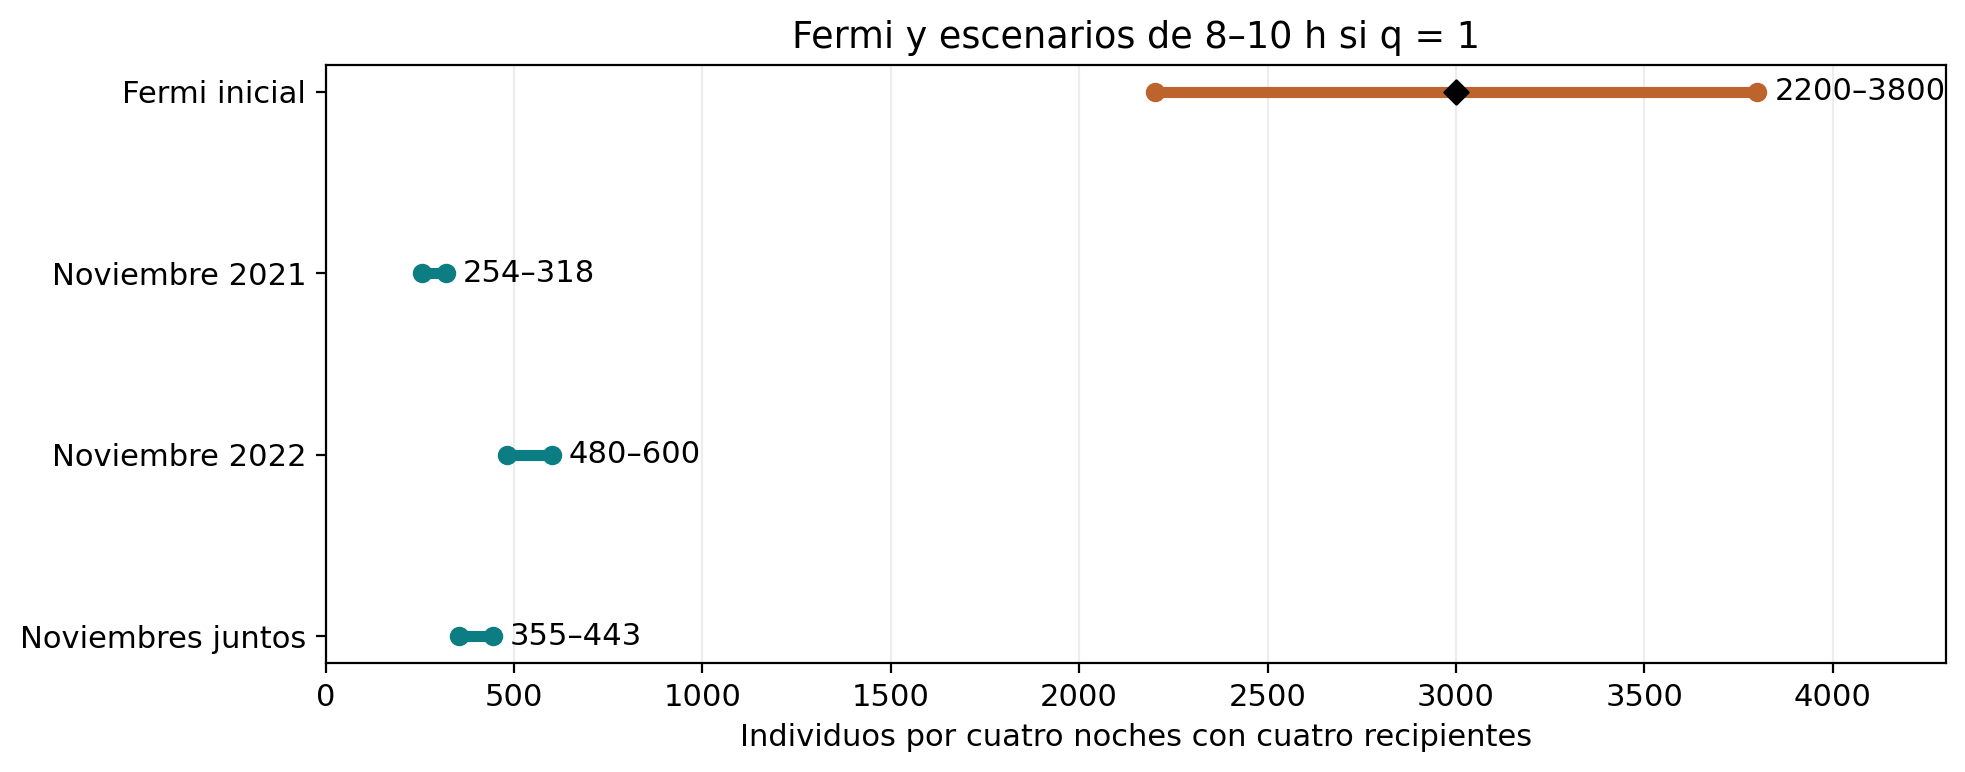

In [9]:
figFermiPropia, ax = plt.subplots(figsize=(10, 4))
etiquetas = ["Fermi inicial", "Noviembre 2021", "Noviembre 2022", "Noviembres juntos"]
extremos = np.vstack([
    [fermiOriginal - margenOriginal, fermiOriginal + margenOriginal],
    visitasNoviembre.tasa.to_numpy(dtype=float)[:, None] * esfuerzoPropio,
    escenarioNoviembre
])
for i, (bajo, alto) in enumerate(extremos):
    ax.plot([bajo, alto], [i, i], "o-", lw=4, color="#bd642c" if i == 0 else "#0c7d82")
    ax.text(alto + 45, i, f"{bajo:.0f}–{alto:.0f}", va="center")
ax.scatter(fermiOriginal, 0, color="black", marker="D", zorder=4)
ax.set_yticks(range(len(etiquetas)), etiquetas)
ax.set(xlabel="Individuos por cuatro noches con cuatro recipientes",
       xlim=(0, 4300), title="Fermi y escenarios de 8–10 h si q = 1")
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.22)
figFermiPropia.tight_layout()
plt.show()

### ¿Qué cambia entre Chete1 y Chete2?

Son dos puntos del estudio junto al río Timbiquí. El mapa muestra los dos noviembres; la sección 6.2 compara sus tasas en las mismas visitas. Sus nombres no significan «interior/exterior» ni «población/mina».

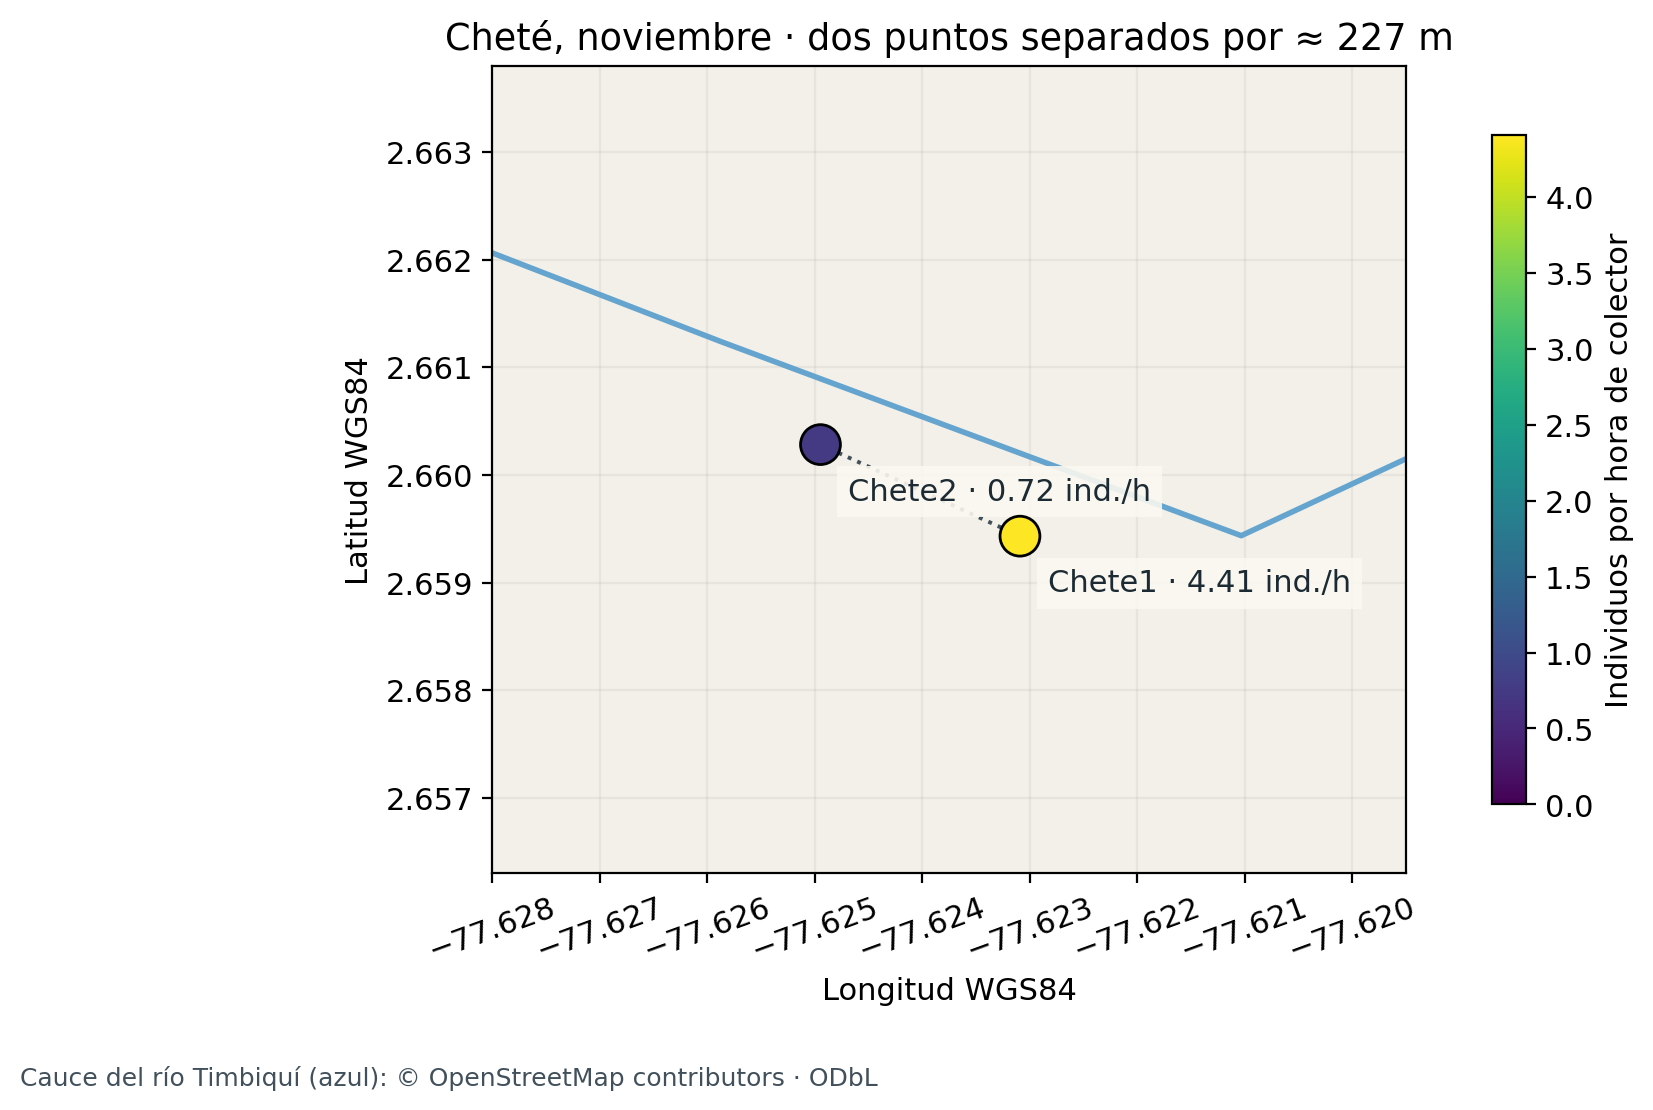

In [10]:
archivoMapa = datos / "cauces_pacifico.geojson"
with archivoMapa.open(encoding="utf-8") as fuenteMapa:
    cauces = json.load(fuenteMapa)
assert any(f["properties"]["name"] == "Río Timbiquí" for f in cauces["features"])

def dibujarCauces(eje):
    for tramo in cauces["features"]:
        lon, lat = np.asarray(tramo["geometry"]["coordinates"]).T
        eje.plot(lon, lat, color="#65a4ce", lw=2, zorder=1)
    eje.set_facecolor("#f2f0e8")
    eje.set(xlabel="Longitud WGS84", ylabel="Latitud WGS84")
    eje.ticklabel_format(style="plain", useOffset=False)
    eje.grid(alpha=0.18)
    eje.set_axisbelow(True)

def distanciaMetros(latitud, longitud):
    lat1, lat2 = np.radians(latitud)
    lon1, lon2 = np.radians(longitud)
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371000 * np.arcsin(np.sqrt(min(1, a)))

coordenadas = d[["parentEventID", "decimalLatitude", "decimalLongitude", "geodeticDatum"]].drop_duplicates()
assert coordenadas.parentEventID.is_unique and coordenadas.geodeticDatum.eq("WGS84").all()
for campo in ["decimalLatitude", "decimalLongitude"]:
    coordenadas[campo] = pd.to_numeric(coordenadas[campo], errors="raise").astype(float)
assert coordenadas.decimalLatitude.between(-90, 90).all()
assert coordenadas.decimalLongitude.between(-180, 180).all()
distanciaChete = distanciaMetros(coordenadas.decimalLatitude, coordenadas.decimalLongitude)
mapaChete = puntosNoviembre.groupby("parentEventID", as_index=False).agg(
    conteo=("conteo", "sum"), esfuerzo=("esfuerzo", "sum")
).merge(coordenadas, on="parentEventID", validate="one_to_one")
mapaChete["tasa"] = mapaChete.conteo / mapaChete.esfuerzo

figMapaChete, ax = plt.subplots(figsize=(9, 5.6))
dibujarCauces(ax)
marcas = ax.scatter(mapaChete.decimalLongitude, mapaChete.decimalLatitude,
                    c=mapaChete.tasa, s=206, cmap="viridis", vmin=0,
                    edgecolors="black", zorder=4)
for fila in mapaChete.itertuples():
    ax.annotate(f"{fila.parentEventID} · {fila.tasa:.2f} ind./h",
                (fila.decimalLongitude, fila.decimalLatitude), xytext=(10, -20),
                textcoords="offset points", color="#1c2b33", fontsize=11,
                bbox={"facecolor": "#faf8f0", "edgecolor": "none", "alpha": .9})
ax.plot(coordenadas.decimalLongitude, coordenadas.decimalLatitude,
        color="#41505b", ls=":", lw=1.4, zorder=2)
ax.set(xlim=(-77.628, -77.6195), ylim=(2.6563, 2.6638),
       title=f"Cheté, noviembre · dos puntos separados por ≈ {distanciaChete:.0f} m")
ax.set_aspect(1 / np.cos(np.radians(coordenadas.decimalLatitude.mean())))
ax.tick_params(axis="x", labelrotation=20)
figMapaChete.colorbar(marcas, ax=ax, label="Individuos por hora de colector", shrink=.83)
figMapaChete.text(.02, .02, "Cauce del río Timbiquí (azul): © OpenStreetMap contributors · ODbL",
                  fontsize=9, color="#41505b")
figMapaChete.tight_layout(rect=(0, .06, 1, 1))
plt.show()

### La imagen del equipo

<img src="Datos/cete.png" width="430" alt="Vista anotada de Cheté: estrella roja, Chete1; amarilla, Chete2; sombreado morado, sector señalado por el equipo.">

La estrella roja identifica Chete1 y la amarilla, Chete2. El equipo señala en morado un sector de mayor cercanía a una zona de minería ilegal. Es una referencia visual, no una exposición medida por el estudio.

## 6. ¿Qué conviene ampliar para entrenar?

En A mantenemos Cheté y variamos los meses; en B mantenemos noviembre y variamos las localidades de Timbiquí. Comparamos la dispersión relativa de las tasas: desviación estándar dividida por su media, dando igual peso a cada grupo y luego a cada año. Revisamos el resultado con solo jornadas de doce horas y con el rango intercuartílico dividido por la mediana.

In [11]:
claveEvento = ["county", "locality", "eventID"]
camposSitio = ["county", "locality"]
localidadObjetivo = "Timbiquí · Cheté"
corteFinal = pd.Timestamp("2023-01-01")

fechas = calendario.eventDate.str.split("/")
calendario["inicio"] = pd.to_datetime(fechas.str[0], errors="coerce")
calendario["fin"] = pd.to_datetime(fechas.str[-1], errors="coerce")
assert calendario.loc[calendario.eventDate.notna(), ["inicio", "fin"]].notna().all().all()
assert calendario.fin.dropna().ge(calendario.inicio.dropna()).all()
fechasEvento = calendario.groupby(claveEvento, as_index=False).agg(
    inicio=("inicio", "min"), fin=("fin", "max")
)
fechasFilas = calendario[claveEvento].join(
    fechasEvento.set_index(claveEvento), on=claveEvento, validate="many_to_one"
)
assert len(fechasFilas) == len(calendario)
filasAntes = set(fechasFilas.index[fechasFilas.fin.lt(corteFinal)])
assert filasReserva.isdisjoint(filasAntes) and filasDesarrollo.issubset(filasAntes)

def reconstruirEventos(datos):
    datos = datos.copy()
    conteos = pd.to_numeric(datos.individualCount, errors="raise")
    assert conteos.notna().all() and conteos.ge(0).all() and conteos.mod(1).eq(0).all()
    datos["conteo"] = conteos.astype(int)
    esfuerzo = datos.samplingEffort.str.extract(r"^(\d+) h por noche, (\d+) noches?$")
    datos[["horas", "noches"]] = esfuerzo.astype(int)
    assert datos.occurrenceID.is_unique and datos[claveEvento].notna().all().all()
    assert datos[["horas", "noches"]].gt(0).all().all()
    assert datos.genus.eq("Anopheles").all()
    assert datos.samplingProtocol.eq("Aspirador bucal | Colecta con cebo humano").all()
    assert datos.groupby(claveEvento)[["horas", "parentEventID"]].nunique().eq(1).all().all()
    eventos = datos.groupby(claveEvento, as_index=False).agg(
        conteo=("conteo", "sum"), horas=("horas", "first"),
        noches=("noches", "max"), punto=("parentEventID", "first"),
        registros=("occurrenceID", "size"),
    ).merge(fechasEvento, on=claveEvento, validate="one_to_one")
    eventos["esfuerzo"] = 2 * eventos.horas * eventos.noches
    periodo = eventos.inicio.dt.to_period("M")
    eventos["fecha"] = periodo.where(periodo.eq(eventos.fin.dt.to_period("M"))).dt.to_timestamp()
    assert eventos.conteo.sum() == datos.conteo.sum()
    return eventos

eventosDesarrollo = reconstruirEventos(leerFilas(filasAntes))
assert eventosDesarrollo.fin.lt(corteFinal).all()
assert not eventosDesarrollo.eventID.isin(eventosReserva).any()

CV (%)  RIC/mediana (%)
Regla               Opción                         
Todos los esfuerzos A        47.80            50.51
                    B        63.46            94.83
Solo 12 horas       A        52.06            59.45
                    B        63.46            94.83

Elegimos A: Cheté, todos los meses. CV promedio A = 47.8 %, B = 63.5 %.
Menor CV por año: {2021: 'B', 2022: 'A'}


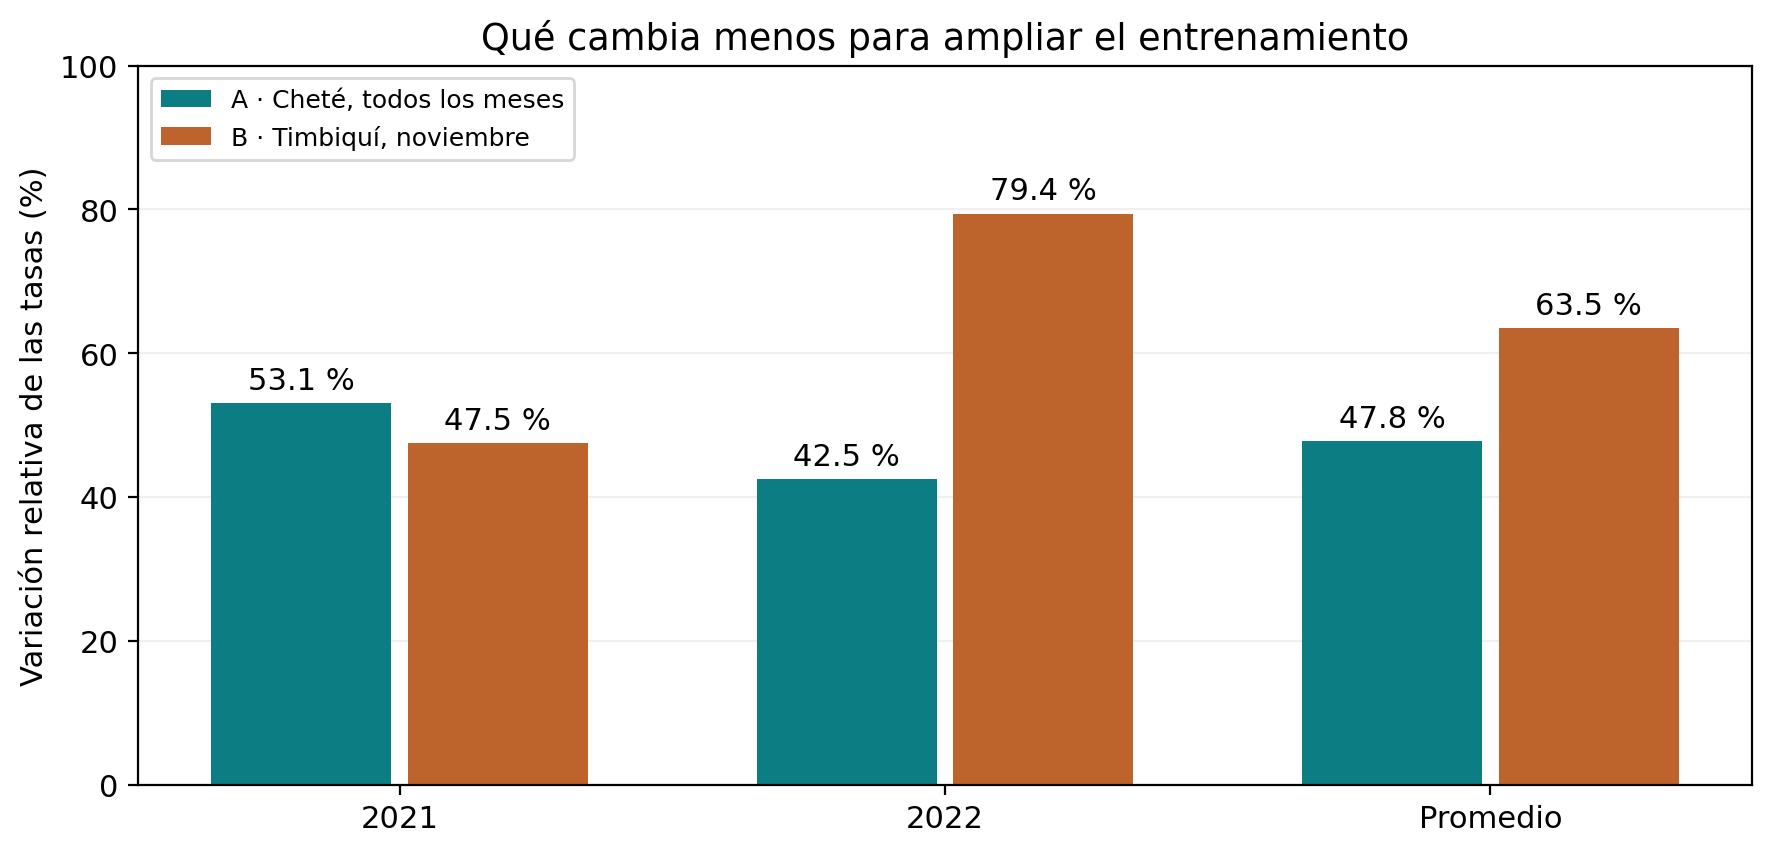

In [12]:
def tasasDeGrupos(eventos, claves):
    grupos = eventos.groupby(claves, as_index=False).agg(
        conteo=("conteo", "sum"), esfuerzo=("esfuerzo", "sum"),
        eventos=("eventID", "size"),
    )
    grupos["tasa"] = grupos.conteo / grupos.esfuerzo
    return grupos

opciones = {"A": "Cheté, todos los meses", "B": "Timbiquí, noviembre"}

def gruposVariacion(eventos):
    claros = eventos.loc[eventos.fecha.notna()].copy()
    claros["anio"] = claros.fecha.dt.year
    enChete = claros.loc[claros.locality.eq("Cheté") & claros.county.eq("Timbiquí")]
    enNoviembre = claros.loc[claros.county.eq("Timbiquí") & claros.fecha.dt.month.eq(mesPropuesto)]
    return {
        "A": tasasDeGrupos(enChete, ["anio", "fecha"]),
        "B": tasasDeGrupos(enNoviembre, ["anio", "locality"]),
    }

def medirDispersion(grupos, regla):
    filas = []
    for opcion, tabla in grupos.items():
        for anio, parte in tabla.groupby("anio"):
            x = parte.tasa
            filas.append({
                "Opción": opcion, "Año": int(anio), "Regla": regla, "Grupos": len(x),
                "Promedio de tasas": x.mean(), "Mínimo": x.min(), "Máximo": x.max(),
                "CV (%)": 100 * x.std(ddof=1) / x.mean(),
                "RIC/mediana (%)": 100 * (x.quantile(.75) - x.quantile(.25)) / x.median(),
            })
    return pd.DataFrame(filas)

gruposPrincipales = gruposVariacion(eventosDesarrollo)
dispersionAnual = medirDispersion(gruposPrincipales, "Todos los esfuerzos")
dispersion12 = medirDispersion(
    gruposVariacion(eventosDesarrollo.loc[eventosDesarrollo.horas.eq(12)]),
    "Solo 12 horas"
)
assert dispersionAnual.groupby("Opción").Año.nunique().eq(2).all()
resumenVariacion = pd.concat([dispersionAnual, dispersion12]).groupby(
    ["Regla", "Opción"], sort=False
)[["CV (%)", "RIC/mediana (%)"]].mean()
display(resumenVariacion)
cvPrincipal = resumenVariacion.loc["Todos los esfuerzos", "CV (%)"]
opcionElegida = cvPrincipal.idxmin()
cvAnual = dispersionAnual.pivot(index="Año", columns="Opción", values="CV (%)")
print(f"Elegimos {opcionElegida}: {opciones[opcionElegida]}. "
      f"CV promedio A = {cvPrincipal['A']:.1f} %, B = {cvPrincipal['B']:.1f} %.")
print("Menor CV por año:", cvAnual.idxmin(axis=1).to_dict())

figVariacion, ax = plt.subplots(figsize=(9, 4.4))
desplazamientos = {"A": -.18, "B": .18}
coloresOpciones = {"A": "#0c7d82", "B": "#bd642c"}
for opcion in opciones:
    serie = [*cvAnual[opcion], cvPrincipal[opcion]]
    barras = ax.bar(np.arange(3) + desplazamientos[opcion], serie, width=.33,
                   color=coloresOpciones[opcion], label=f"{opcion} · {opciones[opcion]}")
    ax.bar_label(barras, labels=[f"{v:.1f} %" for v in serie], padding=3)
ax.set(ylim=(0, 100), ylabel="Variación relativa de las tasas (%)",
       title="Qué cambia menos para ampliar el entrenamiento")
ax.set_xticks(range(3), [*cvAnual.index.astype(str), "Promedio"])
ax.legend(loc="upper left", fontsize=9)
ax.grid(axis="y", alpha=.18)
ax.set_axisbelow(True)
figVariacion.tight_layout()
plt.show()

### 6.1. ¿Cuánta incertidumbre tiene la media?

A varía menos en promedio, aunque B gana en 2021. Por eso el bosque focal aprende de todos los meses anteriores de Cheté; el contraste de Fermi sigue limitado a noviembre.

Para el promedio histórico local remuestreamos 19 visitas completas en 5000 réplicas. Cada bloque conserva dos o tres visitas consecutivas y ambos puntos. En cada réplica recalculamos la razón de totales; sus percentiles 2,5 y 97,5 forman el IC aproximado del 95 %. No es un intervalo para una visita futura.

19 visitas: 6540 individuos / 2988 h de colector. Promedio equivalente a 96 h: 210.12.


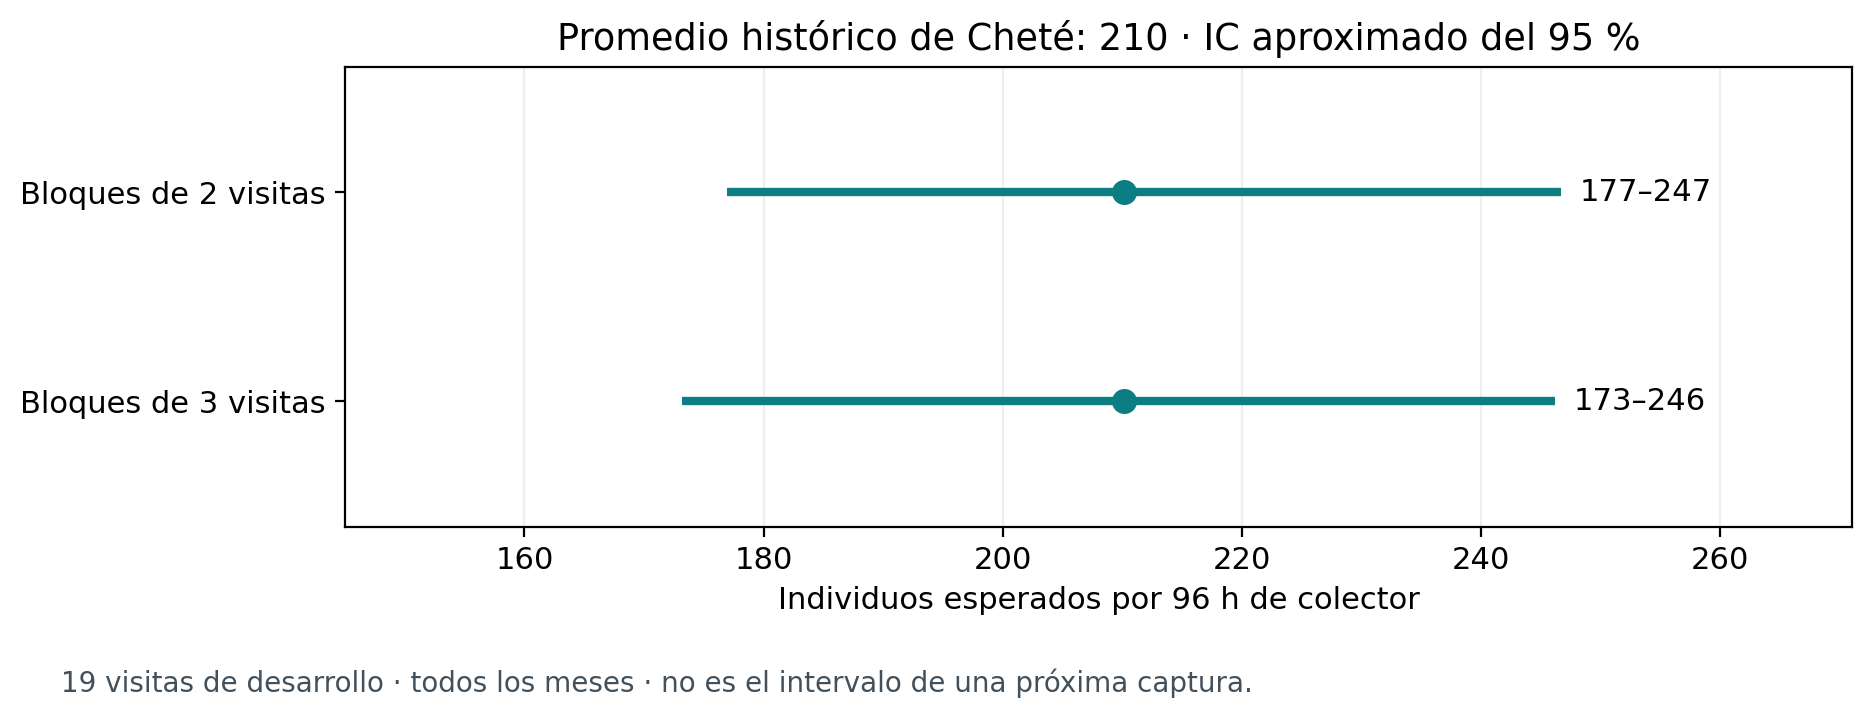

In [13]:
def indicesBloques(cantidad, largo, repeticiones=5000):
    azar = np.random.default_rng(semilla)
    inicios = azar.integers(0, cantidad - largo + 1,
                           size=(repeticiones, math.ceil(cantidad / largo)))
    return (inicios[:, :, None] + np.arange(largo)).reshape(repeticiones, -1)[:, :cantidad]

visitasOrdenadas = visitas.sort_values("fecha")
conteosHistoricos = visitasOrdenadas.conteo.to_numpy(dtype=float)
horasHistoricas = visitasOrdenadas.esfuerzo.to_numpy(dtype=float)
mediaHistorica96 = esfuerzoObjetivo * conteosHistoricos.sum() / horasHistoricas.sum()
limitesMedia = []
for largo in (2, 3):
    indices = indicesBloques(len(visitasOrdenadas), largo)
    simuladas = esfuerzoObjetivo * conteosHistoricos[indices].sum(axis=1) / horasHistoricas[indices].sum(axis=1)
    bajo, alto = np.percentile(simuladas, [2.5, 97.5])
    limitesMedia.append([largo, mediaHistorica96, bajo, alto])
icMediaHistorica = pd.DataFrame(limitesMedia, columns=[
    "Visitas por bloque", "Estimación", "IC 95 % inferior", "IC 95 % superior"
]).set_index("Visitas por bloque")
print(f"{len(visitasOrdenadas)} visitas: {conteosHistoricos.sum():.0f} individuos / "
      f"{horasHistoricas.sum():.0f} h de colector. Promedio equivalente a 96 h: {mediaHistorica96:.2f}.")

figConfianza, ax = plt.subplots(figsize=(9.5, 3.6))
for i, (largo, fila) in enumerate(icMediaHistorica.iterrows()):
    bajo, alto = fila["IC 95 % inferior"], fila["IC 95 % superior"]
    ax.hlines(i, bajo, alto, color="#0c7d82", lw=3)
    ax.scatter(mediaHistorica96, i, color="#0c7d82", s=64, zorder=3)
    ax.annotate(f"{bajo:.0f}–{alto:.0f}", (alto, i), xytext=(7, 0),
                textcoords="offset points", va="center")
ax.set_yticks([0, 1], ["Bloques de 2 visitas", "Bloques de 3 visitas"])
ax.set(xlim=(145, 271), ylim=(1.6, -.6), xlabel="Individuos esperados por 96 h de colector",
       title=f"Promedio histórico de Cheté: {mediaHistorica96:.0f} · IC aproximado del 95 %")
ax.grid(axis="x", alpha=.2)
figConfianza.text(.04, .022, "19 visitas de desarrollo · todos los meses · no es el intervalo de una próxima captura.",
                  color="#41505b", fontsize=10)
figConfianza.tight_layout(rect=(0, .08, 1, 1))
plt.show()

### 6.2. Los dos puntos, cara a cara

Comparamos primero sus tasas acumuladas en desarrollo. Después restamos Chete2 a Chete1 dentro de cada visita: así una época abundante no se confunde con un cambio de punto. Comprobamos el resultado con bloques de visitas y sin las jornadas iniciales de 14 horas.

In [14]:
resumenSitios = puntos.groupby("parentEventID")[["conteo", "esfuerzo"]].sum()
resumenSitios["tasa"] = resumenSitios.conteo / resumenSitios.esfuerzo
resumenSitios["Por 96 h"] = esfuerzoObjetivo * resumenSitios.tasa
display(resumenSitios.rename_axis("Punto").rename(columns={
    "conteo": "Individuos", "esfuerzo": "Horas de colector", "tasa": "Individuos/h"
}))

parejas = puntos.pivot(index="visita", columns="parentEventID", values="cuatroNoches")
assert parejas.notna().all().all()
diferencias = (parejas.Chete1 - parejas.Chete2).to_numpy(dtype=float)
chete12 = puntos.loc[puntos.horas.eq(12)].pivot(
    index="visita", columns="parentEventID", values="cuatroNoches"
).dropna()
sinBase = (chete12.Chete1 - chete12.Chete2).to_numpy(dtype=float)
filasIntervalo = []
for etiqueta, observado in [("Todas las visitas", diferencias), ("Solo jornadas de 12 h", sinBase)]:
    for largo in [2, 3]:
        muestras = observado[indicesBloques(len(observado), largo)].mean(axis=1)
        bajo, alto = np.quantile(muestras, [.025, .975])
        filasIntervalo.append([etiqueta, len(observado), largo, observado.mean(), bajo, alto])
intervalosPuntos = pd.DataFrame(filasIntervalo, columns=[
    "Muestra", "Visitas", "Bloque", "Diferencia media", "Límite 95 % bajo", "Límite 95 % alto"
])
icPareja = intervalosPuntos.iloc[0]
print(f"Diferencia media emparejada (Chete1 menos Chete2): {diferencias.mean():.0f} por 96 h; "
      f"IC 95 % aproximado con bloques de dos: {icPareja['Límite 95 % bajo']:.0f}–"
      f"{icPareja['Límite 95 % alto']:.0f}. El menor límite inferior entre las cuatro "
      f"comprobaciones es {intervalosPuntos['Límite 95 % bajo'].min():.0f}.")
sinUnaVisita = np.array([np.delete(diferencias, i).mean() for i in range(len(diferencias))])
print(f"Chete1 tiene mayor tasa en {(diferencias > 0).sum()} de {len(diferencias)} visitas. "
      "Las diferencias e intervalos están en individuos por 96 horas de colector.")
print(f"Mediana de las diferencias emparejadas: {np.median(diferencias):.0f}. "
      f"Al retirar una visita cada vez, la diferencia media va de {sinUnaVisita.min():.0f} "
      f"a {sinUnaVisita.max():.0f}; esos extremos no son un IC.")

,Individuos,Horas de colector,Individuos/h,Por 96 h
Punto,,,,
Chete1,5349,1556,3.44,330.02
Chete2,1191,1432,0.83,79.84


Diferencia media emparejada (Chete1 menos Chete2): 252 por 96 h; IC 95 % aproximado con bloques de dos: 172–347. El menor límite inferior entre las cuatro comprobaciones es 172.
Chete1 tiene mayor tasa en 18 de 19 visitas. Las diferencias e intervalos están en individuos por 96 horas de colector.
Mediana de las diferencias emparejadas: 243. Al retirar una visita cada vez, la diferencia media va de 227 a 268; esos extremos no son un IC.


La diferencia entre puntos persiste al excluir la línea base o una visita. Eso describe estos dos sitios; la imagen no demuestra una explicación minera.

## 7. Random Forest: predicción e importancia de variables

Queríamos saber cuánto se podía predecir y qué variables ayudaban a hacerlo. El bosque regional aprende de todas las localidades elegibles; el focal A, de Cheté. Cada uno estima la tasa y la escala a 96 h. Usa localidad, fecha y última tasa conocida, con el esfuerzo como peso. Solo entran visitas terminadas antes del corte. Fijamos 200 árboles, profundidad tres y un mínimo de tres visitas por hoja para ambos.

En diez meses de 2022 simulamos pronósticos hacia adelante. Comparamos su error absoluto medio (MAE) con la tasa histórica y la última visita de Cheté. Para los intervalos repetimos el ejercicio al adelanto correspondiente; la elección A/B se hizo con todo el desarrollo, de modo que 2022 no es una prueba independiente de esa elección.

In [15]:
def formarCampanas(eventos):
    claros = eventos.loc[eventos.fecha.notna()]
    campanas = claros.groupby(camposSitio + ["fecha"], as_index=False).agg(
        conteo=("conteo", "sum"), esfuerzo=("esfuerzo", "sum"), fin=("fin", "max"),
        eventos=("eventID", "size"),
    )
    campanas["tasa"] = campanas.conteo / campanas.esfuerzo
    campanas["sitio"] = campanas.county.str.cat(campanas.locality, sep=" · ")
    assert campanas.fin.lt(campanas.fecha + pd.offsets.MonthBegin()).all()
    return campanas.sort_values(["fecha", "sitio"]).reset_index(drop=True)

campanasDesarrollo = formarCampanas(eventosDesarrollo)
cheteDesarrollo = campanasDesarrollo.loc[campanasDesarrollo.sitio.eq(localidadObjetivo)]
assert len(cheteDesarrollo) == len(visitas)
assert cheteDesarrollo.eventos.eq(2).all()
assert np.allclose(cheteDesarrollo.tasa, visitas.tasa)

bosqueRegional = "Bosque regional"
bosqueFocal = f"Bosque focal ({opcionElegida})"
nombreHistorica = "Fermi revisada (tasa histórica)"
nombreUltima = "Última visita"
nombresBosques = [bosqueRegional, bosqueFocal]
metodos = [*nombresBosques, nombreHistorica, nombreUltima]
numericasBosque = ["tiempo", "senoMes", "cosenoMes", "tasaAnterior"]
parametrosBosque = dict(n_estimators=200, max_depth=3, min_samples_leaf=3,
                       random_state=semilla, n_jobs=1)

def ambitoFocal(historia):
    if opcionElegida == "A":
        return historia.loc[historia.sitio.eq(localidadObjetivo)]
    return historia.loc[historia.county.eq("Timbiquí") & historia.fecha.dt.month.eq(mesPropuesto)]

def entradasBosque(campanas, tasaAnterior):
    mes = campanas.fecha.dt.month.to_numpy()
    angulo = 2 * np.pi * (mes - 1) / 12
    return pd.DataFrame({
        "sitio": campanas.sitio.to_numpy(),
        "tiempo": (campanas.fecha.dt.year.to_numpy() - 2021) * 12 + mes - 1,
        "senoMes": np.sin(angulo), "cosenoMes": np.cos(angulo),
        "tasaAnterior": np.asarray(tasaAnterior, dtype=float),
    })

def ajustarBosques(historia, corte):
    assert historia.fin.lt(corte).all()
    ajustes = {}
    for nombre, datos in [(bosqueRegional, historia), (bosqueFocal, ambitoFocal(historia))]:
        datos = datos.sort_values(["fecha", "sitio"])
        previa = datos.groupby("sitio").tasa.shift().fillna(-1)
        codificar = ColumnTransformer([
            ("calendario_y_historia", "passthrough", numericasBosque),
            ("lugar", OneHotEncoder(handle_unknown="ignore"), ["sitio"]),
        ])
        modelo = make_pipeline(codificar, RandomForestRegressor(**parametrosBosque))
        modelo.fit(entradasBosque(datos, previa), datos.tasa,
                   randomforestregressor__sample_weight=datos.esfuerzo)
        ultimaPorSitio = datos.groupby("sitio").tasa.last()
        ajustes[nombre] = (modelo, ultimaPorSitio, len(datos))
    return ajustes

def pronosticar(ajustes, historia, objetivos):
    xBosques, pred = {}, {}
    for nombre, (modelo, ultimaPorSitio, _) in ajustes.items():
        anterior = objetivos.sitio.map(ultimaPorSitio).fillna(-1)
        xBosques[nombre] = entradasBosque(objetivos, anterior)
        pred[nombre] = esfuerzoObjetivo * modelo.predict(xBosques[nombre])
    che = historia.loc[historia.sitio.eq(localidadObjetivo)].sort_values("fecha")
    pred[nombreHistorica] = esfuerzoObjetivo * che.conteo.sum() / che.esfuerzo.sum()
    pred[nombreUltima] = esfuerzoObjetivo * che.tasa.iloc[-1]
    return pd.DataFrame(pred, index=objetivos.index), xBosques

print("Entradas disponibles antes de salir: localidad, calendario y última tasa disponible.")
print("Configuración fijada para ambos bosques:", parametrosBosque)
print(f"Desarrollo regional: {len(campanasDesarrollo)} visitas localidad–mes, "
      f"con {campanasDesarrollo.sitio.nunique()} etiquetas municipio–localidad.")

Entradas disponibles antes de salir: localidad, calendario y última tasa disponible.
Configuración fijada para ambos bosques: {'n_estimators': 200, 'max_depth': 3, 'min_samples_leaf': 3, 'random_state': 829, 'n_jobs': 1}
Desarrollo regional: 483 visitas localidad–mes, con 27 etiquetas municipio–localidad.


In [16]:
fechasCalibracion = cheteDesarrollo.loc[cheteDesarrollo.fecha.dt.year.eq(2022), "fecha"]
validaciones = []
casosImportancia = {n: [] for n in nombresBosques}
casosRegion = []
ajustesPorCorte = {}

for corte in fechasCalibracion:
    pasado = campanasDesarrollo.loc[campanasDesarrollo.fin.lt(corte)]
    objetivos = campanasDesarrollo.loc[campanasDesarrollo.fecha.eq(corte)]
    esChete = objetivos.sitio.eq(localidadObjetivo).to_numpy()
    assert esChete.sum() == 1
    assert pasado.fin.max() < objetivos.fecha.min()
    ajustes = ajustarBosques(pasado, corte)
    ajustesPorCorte[corte] = (pasado, ajustes)
    estimados, entradas = pronosticar(ajustes, pasado, objetivos)
    observado = esfuerzoObjetivo * objetivos.tasa.to_numpy(dtype=float)
    validaciones.append(estimados.loc[esChete].assign(
        Fecha=corte, Observado=observado[esChete], Corte=corte
    ))
    for nombre in nombresBosques:
        casosImportancia[nombre].append(
            (ajustes[nombre][0], entradas[nombre].loc[esChete], observado[esChete])
        )
    casosRegion.append((ajustes[bosqueRegional][0], entradas[bosqueRegional], observado))


calibracionBosques = pd.concat(validaciones, ignore_index=True)
assert len(calibracionBosques) == len(fechasCalibracion)
erroresBosques = calibracionBosques[metodos].sub(calibracionBosques.Observado, axis=0).abs()

def horizonteMes(fecha, corte):
    return (fecha.year - corte.year) * 12 + fecha.month - corte.month + 1

minimoHistoria = int(cheteDesarrollo.fin.lt(fechasCalibracion.min()).sum())

def origenesComparables(horizonte):
    for fecha in fechasCalibracion:
        corte = fecha - pd.DateOffset(months=horizonte - 1)
        if cheteDesarrollo.fin.lt(corte).sum() >= minimoHistoria:
            assert horizonteMes(fecha, corte) == horizonte
            yield fecha, corte

nivelOrientativo = .80
erroresPorHorizonte = {1: erroresBosques}
for horizonte in (2, 3):
    errores = []
    for fecha, corte in origenesComparables(horizonte):
        if corte not in ajustesPorCorte:
            pasado = campanasDesarrollo.loc[campanasDesarrollo.fin.lt(corte)]
            ajustesPorCorte[corte] = (pasado, ajustarBosques(pasado, corte))
        pasado, ajustes = ajustesPorCorte[corte]
        objetivo = cheteDesarrollo.loc[cheteDesarrollo.fecha.eq(fecha)]
        assert len(objetivo) == 1 and pasado.fin.max() < corte <= fecha
        estimado, _ = pronosticar(ajustes, pasado, objetivo)
        observado = esfuerzoObjetivo * objetivo.tasa.iloc[0]
        errores.append((estimado.iloc[0] - observado).abs())
    erroresPorHorizonte[horizonte] = pd.DataFrame(errores)

filasMargenes = []
for horizonte, errores in erroresPorHorizonte.items():
    posicion = math.ceil((len(errores) + 1) * nivelOrientativo)
    assert posicion <= len(errores)
    margen = errores.apply(lambda e: np.sort(e)[posicion - 1])
    filasMargenes.append({"Adelanto (meses)": horizonte, "Ejercicios": len(errores),
                          "Orden del error": posicion, **margen.to_dict()})
margenesHorizonte = pd.DataFrame(filasMargenes).set_index("Adelanto (meses)")
display(margenesHorizonte)

ajustesFinales = ajustarBosques(campanasDesarrollo, corteFinal)
fechasBloque = pd.to_datetime(sorted(reserva.periodo.unique()))
assert len(fechasBloque) == 3 and fechasBloque.min() == corteFinal
objetivoBloque = pd.DataFrame({"sitio": localidadObjetivo, "fecha": fechasBloque})
predBloque, _ = pronosticar(ajustesFinales, campanasDesarrollo, objetivoBloque)
print("Configuración y márgenes fijados. Corte:", corteFinal.date(),
      "· Alcance focal:", opciones[opcionElegida])
print("Visitas para ajustar antes del bloque:",
      {n: a[2] for n, a in ajustesFinales.items()})

,Ejercicios,Orden del error,Bosque regional,Bosque focal (A),Fermi revisada (tasa histórica),Última visita
Adelanto (meses),,,,,,
1,10,9,193.24,163.19,154.62,235.50
2,9,8,146.18,163.19,154.91,154.29
3,8,8,264.14,231.63,267.96,381.60


Configuración y márgenes fijados. Corte: 2023-01-01 · Alcance focal: Cheté, todos los meses
Visitas para ajustar antes del bloque: {'Bosque regional': 483, 'Bosque focal (A)': 19}


<a id="importancia-random-forest"></a>

### 7.1. ¿Qué variables fueron más importantes para los Random Forest?

Medimos cuánto aumenta el **error absoluto medio (MAE)** al mezclar un predictor en visitas de 2022 que su bosque todavía no había visto. Un valor positivo indica que el predictor ayudaba; uno negativo, que mezclarlo redujo el error en ese ejercicio. El esfuerzo pondera el entrenamiento: no es un predictor.

Mezclamos la **última tasa conocida** entre meses de la misma localidad. Hacemos lo mismo con el **calendario** como grupo (tiempo transcurrido, seno y coseno del mes). Para la **localidad**, intercambiamos sus etiquetas entre las visitas del mismo mes. En Cheté esa etiqueta no cambia y no se puede evaluar. La tabla ordena cada bosque y ámbito por aumento medio del MAE, en individuos por 96 h. P10–P90 describe la variación entre 60 permutaciones; no es un intervalo de confianza.

In [17]:
def importanciaBloques(casos, grupos, porMes=False, repeticiones=60):
    # Cada caso conserva el modelo de su corte y solo tiene datos de validación.
    entradas = pd.concat([x for _, x, _ in casos], ignore_index=True)
    observado = np.concatenate([y for _, _, y in casos])
    tamanos = [len(x) for _, x, _ in casos]
    limites = np.r_[0, np.cumsum(tamanos)]
    tramos = [slice(a, b) for a, b in zip(limites[:-1], limites[1:])]
    base = np.concatenate([
        esfuerzoObjetivo * modelo.predict(x) for modelo, x, _ in casos
    ])
    maeBase = np.abs(base - observado).mean()
    azar = np.random.default_rng(semilla)
    bloques = ([np.arange(t.start, t.stop) for t in tramos] if porMes else
               list(entradas.groupby("sitio", sort=False).indices.values()))
    ordenes = []
    for _ in range(repeticiones):
        orden = np.arange(len(entradas))
        for bloque in bloques:
            orden[bloque] = azar.permutation(bloque)
        ordenes.append(orden)
    resultados = []
    for variable, columnas in grupos.items():
        if entradas[columnas].drop_duplicates().shape[0] == 1:
            continue
        errores = np.zeros(repeticiones)
        for (modelo, originales, _), tramo in zip(casos, tramos):
            lote = pd.concat([originales] * repeticiones, ignore_index=True)
            indices = np.concatenate([orden[tramo] for orden in ordenes])
            lote[columnas] = entradas.iloc[indices][columnas].to_numpy()
            simuladas = esfuerzoObjetivo * modelo.predict(lote).reshape(repeticiones, len(originales))
            errores += np.abs(simuladas - observado[tramo]).sum(axis=1)
        delta = errores / len(observado) - maeBase
        resultados.append([variable, delta.mean(), *np.quantile(delta, [.10, .90])])
    return pd.DataFrame(resultados, columns=["Variable", "Aumento de MAE", "P10", "P90"])

gruposTemporales = {"Calendario": ["tiempo", "senoMes", "cosenoMes"], "Última tasa": ["tasaAnterior"]}
impRegional = pd.concat([
    importanciaBloques(casosRegion, gruposTemporales),
    importanciaBloques(casosRegion, {"Localidad": ["sitio"]}, porMes=True),
], ignore_index=True)
porAmbito = [("Región", bosqueRegional, impRegional)]
for nombre in nombresBosques:
    porAmbito.append(("Cheté", nombre, importanciaBloques(casosImportancia[nombre], gruposTemporales)))
tablaImportancias = pd.concat([
    t.sort_values("Aumento de MAE", ascending=False).assign(Evaluación=ambito, Modelo=modelo)
    for ambito, modelo, t in porAmbito
], ignore_index=True)
nRegionalVal = sum(len(x) for _, x, _ in casosRegion)
nLocalVal = len(casosImportancia[bosqueFocal])
print(f"Validación 2022: {nRegionalVal} visitas localidad–mes en la región, {nLocalVal} en Cheté. "
      "Cambio de MAE frente a las predicciones sin mezclar:")
display(tablaImportancias.set_index(["Evaluación", "Modelo", "Variable"]).round(2))

Validación 2022: 250 visitas localidad–mes en la región, 10 en Cheté. Cambio de MAE frente a las predicciones sin mezclar:


Aumento de MAE    P10    P90
Evaluación Modelo           Variable                                 
Región     Bosque regional  Última tasa           11.16   2.34  20.02
                            Localidad              7.18   4.93   9.04
                            Calendario            -0.84  -2.58   0.91
Cheté      Bosque regional  Calendario            -4.80 -12.92   1.95
                            Última tasa          -12.43 -35.81  11.42
           Bosque focal (A) Última tasa            2.61  -5.66  12.16
                            Calendario             0.64 -10.05   8.35

En la **región**, la última tasa dio el mayor aumento medio del error, seguida de la localidad. El calendario no mostró una mejora consistente. En **Cheté**, los rangos del calendario y de la última tasa cruzan cero en ambos bosques: con diez visitas no tenemos un ganador claro. Esto describe lo que usaron estos modelos, no las causas de las capturas.

**El supuesto que no sobrevivió:** pensábamos usar el bosque para ordenar los factores de nuestra hoja. El ZIP no ofrece por evento color del recipiente, CO₂, señuelo, lluvia ni distancia a una mina, y no conserva conteos separados de interior y exterior. No podemos medir su importancia con estos datos; no significa que su importancia sea cero.

## 8. Cantidad y calendario para la próxima visita

Probamos ahora los cuatro métodos sobre las mismas visitas de enero–marzo de 2023, pronosticadas juntas al cierre de diciembre.

Los intervalos predictivos son orientativos al 80 %. Para cada método y adelanto ordenamos los errores de validación y tomamos el de posición `ceil(0.80 × (n + 1))`. No ajustamos los modelos con la reserva.

Fechas recuperadas en la reserva: 1. Conservamos los registros del mismo evento y especie con identificadores distintos.


,MAE validación 2022,MAE prueba 2023 (por 96 h),Visitas cubiertas (de 3),Ancho medio de intervalo
Bosque regional,112.20,52.80,3,367.51
Bosque focal (A),95.47,95.14,3,372.00
Fermi revisada (tasa histórica),85.50,64.04,3,365.71
Última visita,137.47,44.83,3,381.63


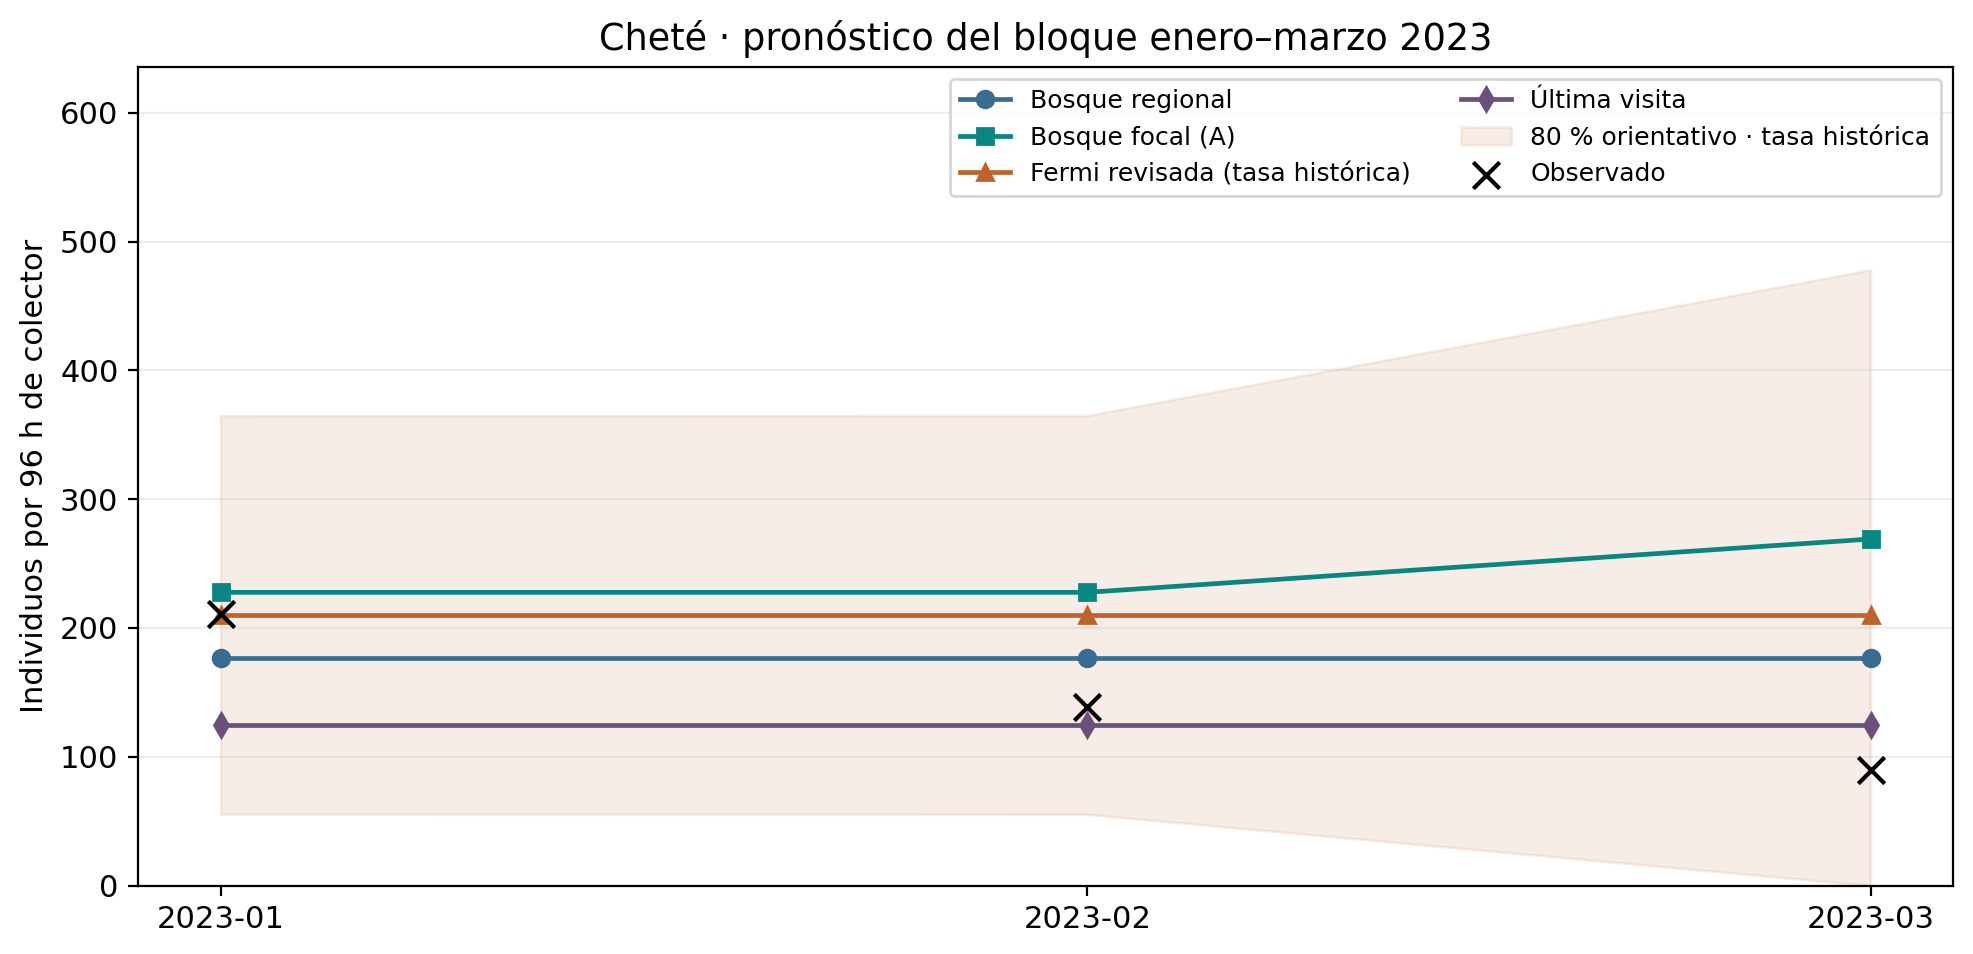

Menor MAE en 2022: Fermi revisada (tasa histórica). Menor MAE en el bloque final: Última visita.
Ningún bosque superó consistentemente las dos referencias.


In [18]:
pruebaOriginal = leerFilas(filasReserva)
assert set(pruebaOriginal.eventID) == eventosReserva
pruebaPreparada = preparar(pruebaOriginal)
_, prueba = agruparVisitas(pruebaPreparada)
assert prueba.visita.tolist() == [20, 21, 22]
assert prueba.fecha.tolist() == fechasBloque.tolist()
assert prueba.inicio.ge(corteFinal).all()
assert campanasDesarrollo.fin.max() < prueba.inicio.min()
print(f"Fechas recuperadas en la reserva: {pruebaPreparada.fechaRecuperada.sum():.0f}. "
      "Conservamos los registros del mismo evento y especie con identificadores distintos.")

observadoBloque = prueba.cuatroNoches.to_numpy(dtype=float)
horizontesBloque = [horizonteMes(fecha, corteFinal) for fecha in fechasBloque]
margenBloque = margenesHorizonte.loc[horizontesBloque, metodos].reset_index(drop=True)
inferiores = (predBloque - margenBloque).clip(lower=0)
superiores = predBloque + margenBloque
cubre = inferiores.le(observadoBloque, axis=0) & superiores.ge(observadoBloque, axis=0)
metricasBosques = pd.DataFrame({
    "MAE (individuos / 96 h)": [
        mean_absolute_error(observadoBloque, predBloque[n]) for n in metodos
    ],
    "Visitas cubiertas (de 3)": cubre.sum(),
    "Ancho medio de intervalo": (superiores - inferiores).mean(),
}, index=metodos)
metricasBosques.insert(0, "MAE validación 2022", erroresBosques.mean().reindex(metodos))
display(metricasBosques.rename(columns={"MAE (individuos / 96 h)": "MAE prueba 2023 (por 96 h)"}))

figPruebaBosques, ax = plt.subplots(figsize=(10, 4.9))
for nombre, color, marca in zip(metodos, ["#3a6c91", "#098681", "#bd642c", "#6c507c"], "os^d"):
    ax.plot(fechasBloque, predBloque[nombre], marker=marca, lw=1.7, color=color, label=nombre)
ax.fill_between(fechasBloque, inferiores[nombreHistorica].to_numpy(), superiores[nombreHistorica].to_numpy(),
                color="#bd642c", alpha=.11, label="80 % orientativo · tasa histórica")
ax.scatter(fechasBloque, observadoBloque, color="black", marker="x", s=90, zorder=5, label="Observado")
ax.set(ylabel="Individuos por 96 h de colector", title="Cheté · pronóstico del bloque enero–marzo 2023")
ax.set_xticks(fechasBloque, fechasBloque.strftime("%Y-%m"))
ax.set_ylim(bottom=0, top=max(observadoBloque.max(), superiores[nombreHistorica].max()) * 1.33)
ax.grid(axis="y", alpha=.22)
ax.legend(loc="upper right", ncol=2, fontsize=9)
figPruebaBosques.tight_layout()
plt.show()

maesBosques = metricasBosques["MAE (individuos / 96 h)"]
ganadorBosques = maesBosques.idxmin()
ganadorCalibracion = erroresBosques.mean().idxmin()
consistentes = [n for n in nombresBosques
                if maesBosques[n] < maesBosques[[nombreUltima, nombreHistorica]].min()
                and erroresBosques[n].mean() < erroresBosques[[nombreUltima, nombreHistorica]].mean().min()]
recomendado = min(consistentes, key=lambda n: erroresBosques[n].mean()) if consistentes else nombreHistorica
veredictoBosques = (f"{recomendado} superó las referencias en ambas comparaciones." if consistentes else
                    "Ningún bosque superó consistentemente las dos referencias.")
print(f"Menor MAE en 2022: {ganadorCalibracion}. Menor MAE en el bloque final: {ganadorBosques}.")
print(veredictoBosques)

### 8.1. ¿El modelo sabe ordenar los meses?

Con datos disponibles hasta marzo de 2022 simulamos de una vez los doce meses siguientes, sin actualizar la última tasa. Evaluamos solo meses observados. En cada par con cantidades distintas por 96 h, acertar el orden vale 1; empatar, ½. Redondeamos al individuo. Una referencia constante obtiene 50 %.

En la región comparamos, para cada par, las mismas localidades y damos igual peso a cada una. Repetimos en Cheté con ambos bosques. Es un solo año de evaluación retrospectiva, con visitas compartidas entre pares; no hay 66 ensayos independientes.

In [19]:
# Ya terminó la evaluación; ahora leemos también los datos de otros sitios de 2023.
regional = leerFilas(set(calendario.index))
eventosRegional = reconstruirEventos(regional)
campanasRegional = formarCampanas(eventosRegional)
cheteCompleto = campanasRegional.loc[campanasRegional.sitio.eq(localidadObjetivo)]
assert len(cheteCompleto) == len(visitas) + len(prueba)
assert np.allclose(cheteCompleto.tasa.tail(3), prueba.tasa)

corteEnsayo = pd.Timestamp("2022-04-01")
finEnsayo = corteEnsayo + pd.DateOffset(years=1)
histEnsayo = campanasRegional.loc[campanasRegional.fin.lt(corteEnsayo)]
ajEnsayo = ajustarBosques(histEnsayo, corteEnsayo)
mesesEnsayo = pd.date_range(corteEnsayo, periods=12, freq="MS")
panelEnsayo = sorted(histEnsayo.sitio.unique())
rejilla = pd.MultiIndex.from_product([mesesEnsayo, panelEnsayo], names=["fecha", "sitio"]).to_frame(index=False)
assert histEnsayo.fin.max() < rejilla.fecha.min()
estEnsayo, _ = pronosticar({bosqueRegional: ajEnsayo[bosqueRegional]}, histEnsayo, rejilla)
localEnsayo = pd.DataFrame({"fecha": mesesEnsayo, "sitio": localidadObjetivo})
estLocal, _ = pronosticar(ajEnsayo, histEnsayo, localEnsayo)
obsEnsayo = campanasRegional.loc[campanasRegional.fecha.isin(mesesEnsayo)].copy()
assert obsEnsayo.fin.max() < finEnsayo
obsEnsayo["cantidad"] = esfuerzoObjetivo * obsEnsayo.tasa
observadas = obsEnsayo.pivot(index="fecha", columns="sitio", values="cantidad").reindex(
    index=mesesEnsayo, columns=panelEnsayo)
prevRegion = rejilla.assign(cantidad=estEnsayo[bosqueRegional]).pivot(
    index="fecha", columns="sitio", values="cantidad")

def concordancia(real, estimado):
    puntosOrden, pares, empates = 0., 0, 0
    for a, b in combinations(real.index, 2):
        comunes = real.loc[[a, b]].dropna(axis=1).columns
        if comunes.empty:
            continue
        signoReal, signoPrevisto = [
            np.sign(np.diff(np.rint(tabla.loc[[a, b], comunes].mean(axis=1))))[0]
            for tabla in (real, estimado)
        ]
        if signoReal == 0:
            continue
        pares += 1
        empates += int(signoPrevisto == 0)
        puntosOrden += .5 if signoPrevisto == 0 else float(signoReal == signoPrevisto)
    assert pares > 0
    return [int(real.notna().any(axis=1).sum()), pares, empates, 100 * puntosOrden / pares]

scoresOrden = {"Región · bosque regional": concordancia(observadas, prevRegion)}
for nombre in [*nombresBosques, nombreHistorica]:
    prev = pd.DataFrame({localidadObjetivo: estLocal[nombre].to_numpy()}, index=mesesEnsayo)
    scoresOrden["Cheté · " + nombre] = concordancia(observadas[[localidadObjetivo]], prev)
pruebaOrden = pd.DataFrame.from_dict(scoresOrden, orient="index", columns=[
    "Meses observados", "Pares comparables", "Empates pronosticados", "Acierto con empates (%)"])
display(pruebaOrden)


,Meses observados,Pares comparables,Empates pronosticados,Acierto con empates (%)
Región · bosque regional,11,55,23,40.91
Cheté · Bosque regional,10,45,3,41.11
Cheté · Bosque focal (A),10,45,18,60.00
Cheté · Fermi revisada (tasa histórica),10,45,45,50.00


### 8.2. Doce meses posibles para las cuatro noches

Repetimos el ejercicio desde el cierre de marzo de 2023, sin resultados posteriores en el ZIP. Para Cheté usamos el método elegido por error en la sección 8. Como esa tasa histórica no depende del mes, **los doce meses empatan**: tener una cifra para noviembre no lo convierte en el mejor mes.

Como contraste, ordenamos el promedio del bosque regional para las mismas localidades, con 96 h en cada una e igual peso por lugar. Es un promedio, no una suma. Empatamos cantidades iguales al individuo y dejamos sin puesto los meses sin visitas históricas. El adelanto cambia con la fecha; los márgenes calculados en Cheté no son intervalos para esta tabla regional.

El resumen del INS declara 25 localidades; el ZIP distingue 27 etiquetas de municipio y localidad. No fusionamos nombres sin una correspondencia confirmada. Comprobamos cuánto cambia el promedio al calcularlo solo para las etiquetas presentes en ambos noviembres.

In [20]:
mesES = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto",
         "septiembre", "octubre", "noviembre", "diciembre"]
corteEscenario = finEnsayo
historiaActualizada = campanasRegional.loc[campanasRegional.fin.lt(corteEscenario)]
assert len(historiaActualizada) == len(campanasRegional)
ajustesActualizados = ajustarBosques(historiaActualizada, corteEscenario)
fechasPlan = pd.date_range(corteEscenario, periods=12, freq="MS")
panelPlan = sorted(historiaActualizada.sitio.unique())
novHistoricos = historiaActualizada.loc[historiaActualizada.fecha.dt.month.eq(mesPropuesto)]
panelDosNov = set.intersection(*(set(g.sitio) for _, g in novHistoricos.groupby("fecha")))
enPanelDosNov = np.array([s in panelDosNov for s in panelPlan])
modeloRegion, ultimaRegion, _ = ajustesActualizados[bosqueRegional]
assert set(panelPlan) == set(ultimaRegion.index)
cantidadesRegion, cantidadesPanelDosNov = [], []
for fecha in fechasPlan:
    sitiosMes = pd.DataFrame({"fecha": fecha, "sitio": panelPlan})
    x = entradasBosque(sitiosMes, sitiosMes.sitio.map(ultimaRegion))
    cantidades = esfuerzoObjetivo * modeloRegion.predict(x)
    cantidadesRegion.append(cantidades.mean())
    cantidadesPanelDosNov.append(cantidades[enPanelDosNov].mean())
aniosReg = historiaActualizada.groupby(historiaActualizada.fecha.dt.month).fecha.nunique()
planRegional = pd.DataFrame({
    "Mes": [mesES[f.month - 1].capitalize() + f" {f.year}" for f in fechasPlan],
    "Individuos / 96 h": np.rint(cantidadesRegion).astype(int),
    "Años con visitas en la región": [int(aniosReg.get(f.month, 0)) for f in fechasPlan],
}, index=fechasPlan)
conDatos = planRegional["Años con visitas en la región"].gt(0)
planRegional["Individuos / 96 h"] = planRegional["Individuos / 96 h"].where(conDatos).astype("Int64")
planRegional["Puesto"] = planRegional["Individuos / 96 h"].astype(float).rank(
    method="min", ascending=False, na_option="keep").astype("Int64")
ordenRegional = planRegional.sort_values("Puesto", kind="stable")
tablaMeses = ordenRegional.set_index("Mes")[["Puesto", "Individuos / 96 h", "Años con visitas en la región"]]
display(tablaMeses.astype(object).where(tablaMeses.notna(), "—"))
conDosAnios = ordenRegional.loc[ordenRegional["Años con visitas en la región"].ge(2)]
cambiaPrimero = (set(ordenRegional.index[ordenRegional.Puesto.eq(1).fillna(False)]) !=
                 set(conDosAnios.index[conDosAnios.Puesto.eq(conDosAnios.Puesto.min())]))
print("¿Cambia el primer puesto regional si exigimos dos años de visitas?", "Sí." if cambiaPrimero else "No.")
deltaPanel = np.abs(np.subtract(cantidadesRegion, cantidadesPanelDosNov))[conDatos.to_numpy()].max()
print(f"Con {len(panelDosNov)} etiquetas compartidas en ambos noviembres en vez de {len(panelPlan)}, "
      f"el promedio cambia a lo sumo {deltaPanel:.1f} individuos por 96 h entre los meses con datos.")

assert recomendado == nombreHistorica  # Regla aplicada arriba al ZIP de esta entrega.
estimadoLocal = esfuerzoObjetivo * cheteCompleto.conteo.sum() / cheteCompleto.esfuerzo.sum()
abrilRecomendado = pd.Series({"Predicción (96 h)": estimadoLocal,
                              "Límite orientativo bajo": max(0, estimadoLocal - margenesHorizonte.at[1, recomendado]),
                              "Límite orientativo alto": estimadoLocal + margenesHorizonte.at[1, recomendado]})
fechaNov = next(f for f in fechasPlan if f.month == mesPropuesto)
horizonteNov = horizonteMes(fechaNov, corteEscenario)
casosNov = list(origenesComparables(horizonteNov))
mesesSinVisita = [m for i, m in enumerate(mesES, 1) if i not in set(cheteCompleto.fecha.dt.month)]
print(f"Cheté: {estimadoLocal:.0f} por cuatro noches en los doce meses. "
      f"Abril 2023, intervalo orientativo del 80 %: {abrilRecomendado.iloc[1]:.0f}–{abrilRecomendado.iloc[2]:.0f}.")
print(f"Noviembre queda a {horizonteNov} meses; solo {sum(f.month == mesPropuesto for f, _ in casosNov)} "
      f"ejercicio de ese adelanto cae en noviembre. No tiene intervalo validado. "
      f"Meses sin visita registrada en Cheté: {', '.join(mesesSinVisita)}.")

,Puesto,Individuos / 96 h,Años con visitas en la región
Mes,,,
Julio 2023,1,307,1
Agosto 2023,2,266,2
Septiembre 2023,3,265,2
Mayo 2023,4,261,2
Octubre 2023,4,261,2
Noviembre 2023,6,260,2
Diciembre 2023,6,260,2
Febrero 2024,6,260,3
Enero 2024,9,259,3


¿Cambia el primer puesto regional si exigimos dos años de visitas? Sí.
Con 25 etiquetas compartidas en ambos noviembres en vez de 27, el promedio cambia a lo sumo 13.2 individuos por 96 h entre los meses con datos.
Cheté: 200 por cuatro noches en los doce meses. Abril 2023, intervalo orientativo del 80 %: 45–354.
Noviembre queda a 8 meses; solo 1 ejercicio de ese adelanto cae en noviembre. No tiene intervalo validado. Meses sin visita registrada en Cheté: junio.


**¿Cuándo ir?** Mantendríamos noviembre para repetir la comparación original, no porque se haya demostrado un máximo. En Cheté, el bosque focal obtuvo 60 % de acierto frente al 50 % de empatar siempre; fueron 45 pares de solo diez meses. En la región, el primer puesto cambia al exigir dos años de datos. Para distinguir meses repetiríamos el mismo calendario durante más años.

Los 200 de la referencia local son **por las cuatro noches completas** del protocolo humano. Los 200 de la Fermi eran **por recipiente y por noche**. Coincide el número, no la unidad.

## 9. ¿Qué cambia al igualar el esfuerzo?

### 9.1. Cheté en noviembre frente al estudio

Las 285 noches explican la escala regional de la Fermi. Para comparar rendimientos, en cambio, damos 96 horas a cada tasa. Todo el ZIP incluye Cheté; en 9.2 lo excluimos de la referencia. Mostramos la diferencia sin fijar un umbral de equivalencia.

In [21]:
localEstricto = eventosRegional.loc[
    eventosRegional.locality.eq("Cheté") & eventosRegional.county.eq("Timbiquí")
    & eventosRegional.fecha.dt.month.eq(mesPropuesto)
]
assert set(localEstricto.eventID) == set(noviembre.eventID)

def resumirAmbito(tabla):
    tasa = tabla.conteo.sum() / tabla.esfuerzo.sum()
    return {
        "Registros": tabla.registros.sum(),
        "Localidades": len(tabla[camposSitio].drop_duplicates()),
        "Puntos (códigos)": len(tabla[camposSitio + ["punto"]].drop_duplicates()),
        "Eventos": len(tabla),
        "Visitas localidad–mes asignables": len(formarCampanas(tabla)),
        "Noches-punto": tabla.noches.sum(),
        "Individuos": tabla.conteo.sum(),
        "Horas de colector": tabla.esfuerzo.sum(),
        "Individuos por hora": tasa,
        "Equivalente a 96 h": tasa * esfuerzoObjetivo,
    }

ambitoEstricto, ambitoCompleto = "Cheté · noviembre", "Todo el ZIP"
contraste = pd.DataFrame({
    ambitoEstricto: resumirAmbito(localEstricto),
    ambitoCompleto: resumirAmbito(eventosRegional),
})
display(contraste.loc[["Registros", "Localidades", "Eventos", "Individuos", "Horas de colector",
                       "Individuos por hora", "Equivalente a 96 h"]].rename(index={"Localidades": "Etiquetas municipio–localidad"}))
etiquetasMunicipio = regional[camposSitio].drop_duplicates().groupby("county").size()
print(f"Metadatos: {localidadesResumen} localidades. Etiquetas en el ZIP: {etiquetasMunicipio.sum()} "
      f"({', '.join(f'{k}: {v}' for k, v in etiquetasMunicipio.items())}).")
tasaTotal = contraste.loc["Individuos por hora", ambitoCompleto]
diferenciaTasa = tasaNoviembre - tasaTotal
razonTasas = tasaNoviembre / tasaTotal
print(f"Cheté en noviembre menos todo el ZIP: {diferenciaTasa:+.2f} individuos/h "
      f"({esfuerzoObjetivo * diferenciaTasa:+.1f} en 96 h; "
      f"{100 * (razonTasas - 1):+.1f} % respecto al ZIP).")
sinFecha = eventosRegional.inicio.isna() | eventosRegional.fin.isna()
mesIncierto = eventosRegional.fecha.isna() & ~sinFecha
print(f"Calendario regional: {sinFecha.sum()} eventos sin fecha, "
      f"{mesIncierto.sum()} con más de un mes posible; siguen en el total, no en los bosques.")
assert len(regional) == registrosResumen
assert eventosRegional.conteo.sum() == individuosResumen  # Cotejo independiente: tabla frente a metadatos.


,Cheté · noviembre,Todo el ZIP
Registros,7.00,1502.00
Etiquetas municipio–localidad,1.00,27.00
Eventos,4.00,889.00
Individuos,1197.00,229394.00
Horas de colector,432.00,70964.00
Individuos por hora,2.77,3.23
Equivalente a 96 h,266.00,310.32


Metadatos: 25 localidades. Etiquetas en el ZIP: 27 (Guapi: 13, Santa Bárbara: 4, Timbiquí: 10).
Cheté en noviembre menos todo el ZIP: -0.46 individuos/h (-44.3 en 96 h; -14.3 % respecto al ZIP).
Calendario regional: 12 eventos sin fecha, 3 con más de un mes posible; siguen en el total, no en los bosques.


In [22]:
biologia = regional.assign(individuos=pd.to_numeric(regional.individualCount, errors="raise"))
composicion = biologia.groupby("scientificName").agg(
    Registros=("occurrenceID", "size"), Individuos=("individuos", "sum")
).sort_values("Individuos", ascending=False)
display(composicion)
assert biologia.sex.eq("Hembra").fillna(False).all()
assert "nuneztovari" in " ".join(metadatos.itertext()).casefold()
assert not regional.scientificName.str.contains("nuneztovari", case=False, na=False).any()

,Registros,Individuos
scientificName,,
Anopheles neivai,823,194356
Anopheles albimanus,504,34424
Anopheles apicimacula,175,614


Las tres especies de la tabla sí aparecen en las capturas. *An. nuneztovari* C se menciona solo en los metadatos. Todos los registros dicen «Hembra»; el ZIP no mide infección.

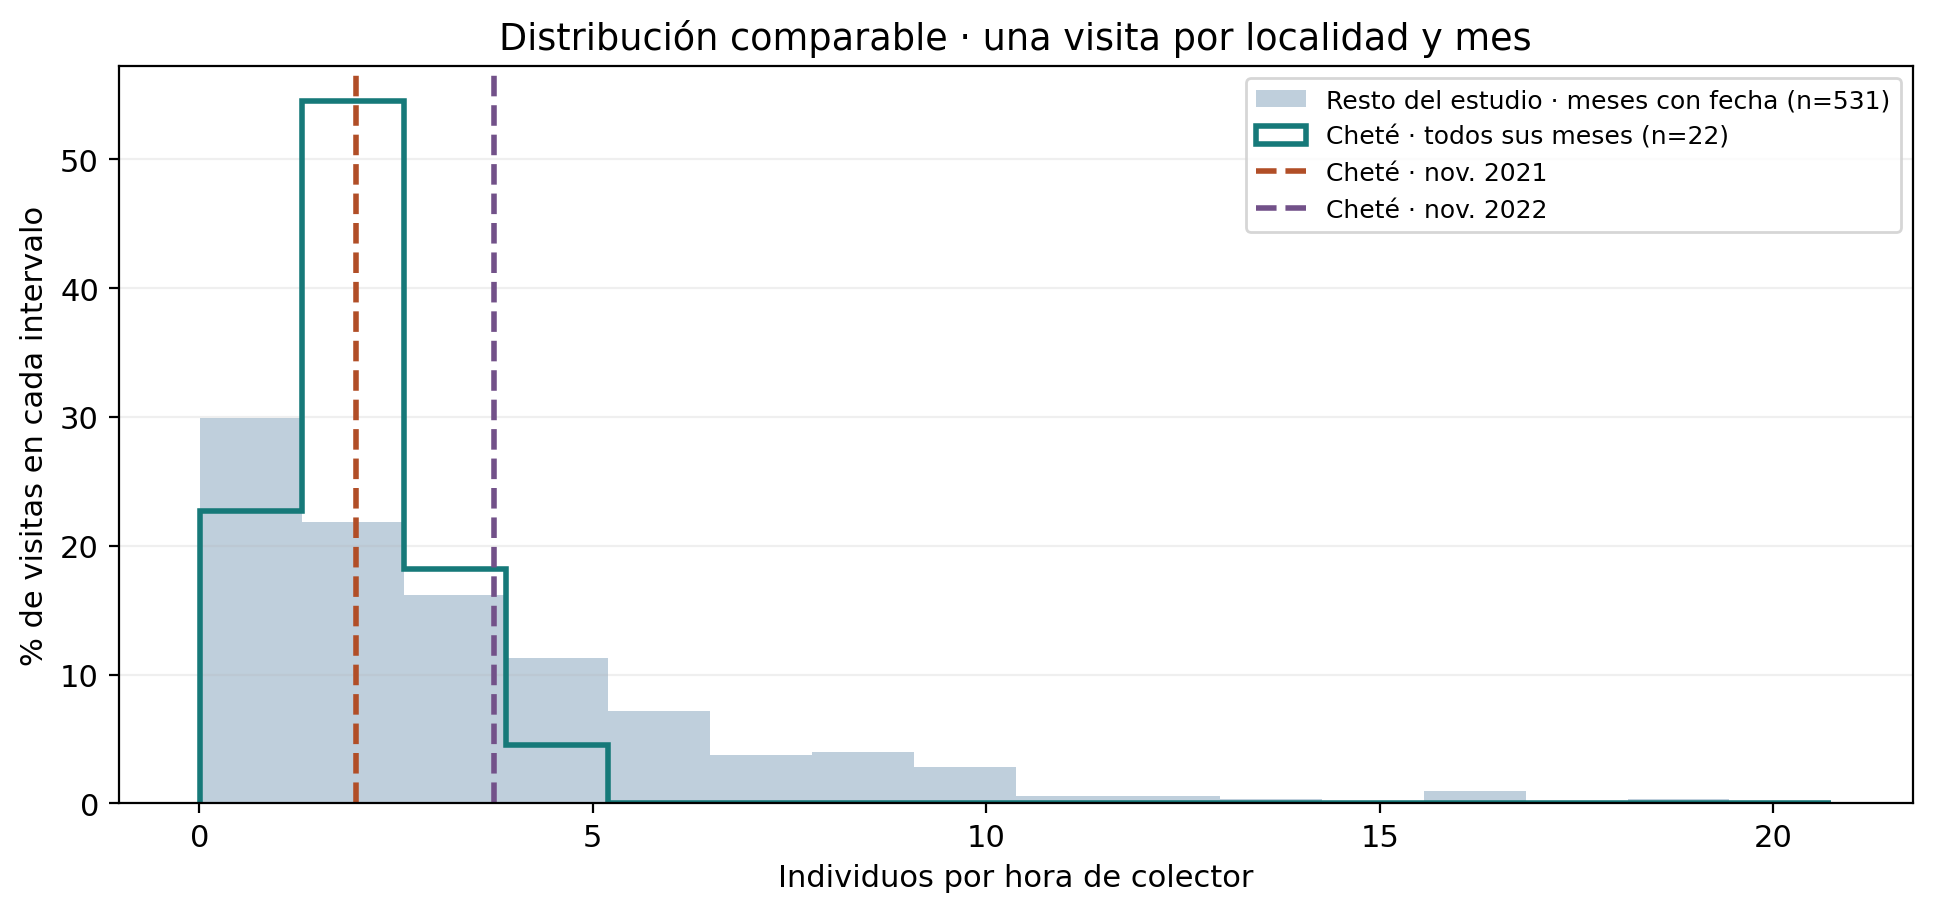

In [23]:
figHistograma, ax = plt.subplots(figsize=(9.8, 4.7))
restoCampanas = campanasRegional.loc[campanasRegional.sitio.ne(localidadObjetivo)]
bordes = np.histogram_bin_edges(campanasRegional.tasa.to_numpy(dtype=float), bins=16)
for tabla, color, estilo, nombre in [
    (restoCampanas, "#49789c", "stepfilled", "Resto del estudio · meses con fecha"),
    (cheteCompleto, "#167979", "step", "Cheté · todos sus meses"),
]:
    tasas = tabla.tasa.to_numpy(dtype=float)
    ax.hist(tasas, bins=bordes, histtype=estilo, linewidth=2,
            weights=np.full(len(tasas), 100 / len(tasas)), color=color,
            alpha=.35 if estilo == "stepfilled" else 1, label=f"{nombre} (n={len(tasas)})")
for fila, color in zip(visitasNoviembre.itertuples(), ["#b14e27", "#725189"]):
    ax.axvline(fila.tasa, color=color, lw=2, ls="--", label=f"Cheté · nov. {fila.fecha.year}")
ax.set(xlabel="Individuos por hora de colector", ylabel="% de visitas en cada intervalo",
       title="Distribución comparable · una visita por localidad y mes")
ax.grid(axis="y", alpha=.2)
ax.legend(loc="upper right", fontsize=9)
figHistograma.tight_layout()
plt.show()

### 9.2. ¿Cambia la respuesta si comparamos los mismos noviembres?

El histograma da a cada grupo su propio 100 %. Ahora comparamos Cheté con sus otros meses y con las localidades externas presentes en ambos noviembres. Calculamos cada tasa por año como individuos divididos por horas; para resumir diferencias damos igual peso a los dos años.

Panel de comparación: 24 localidades externas presentes en ambos noviembres.


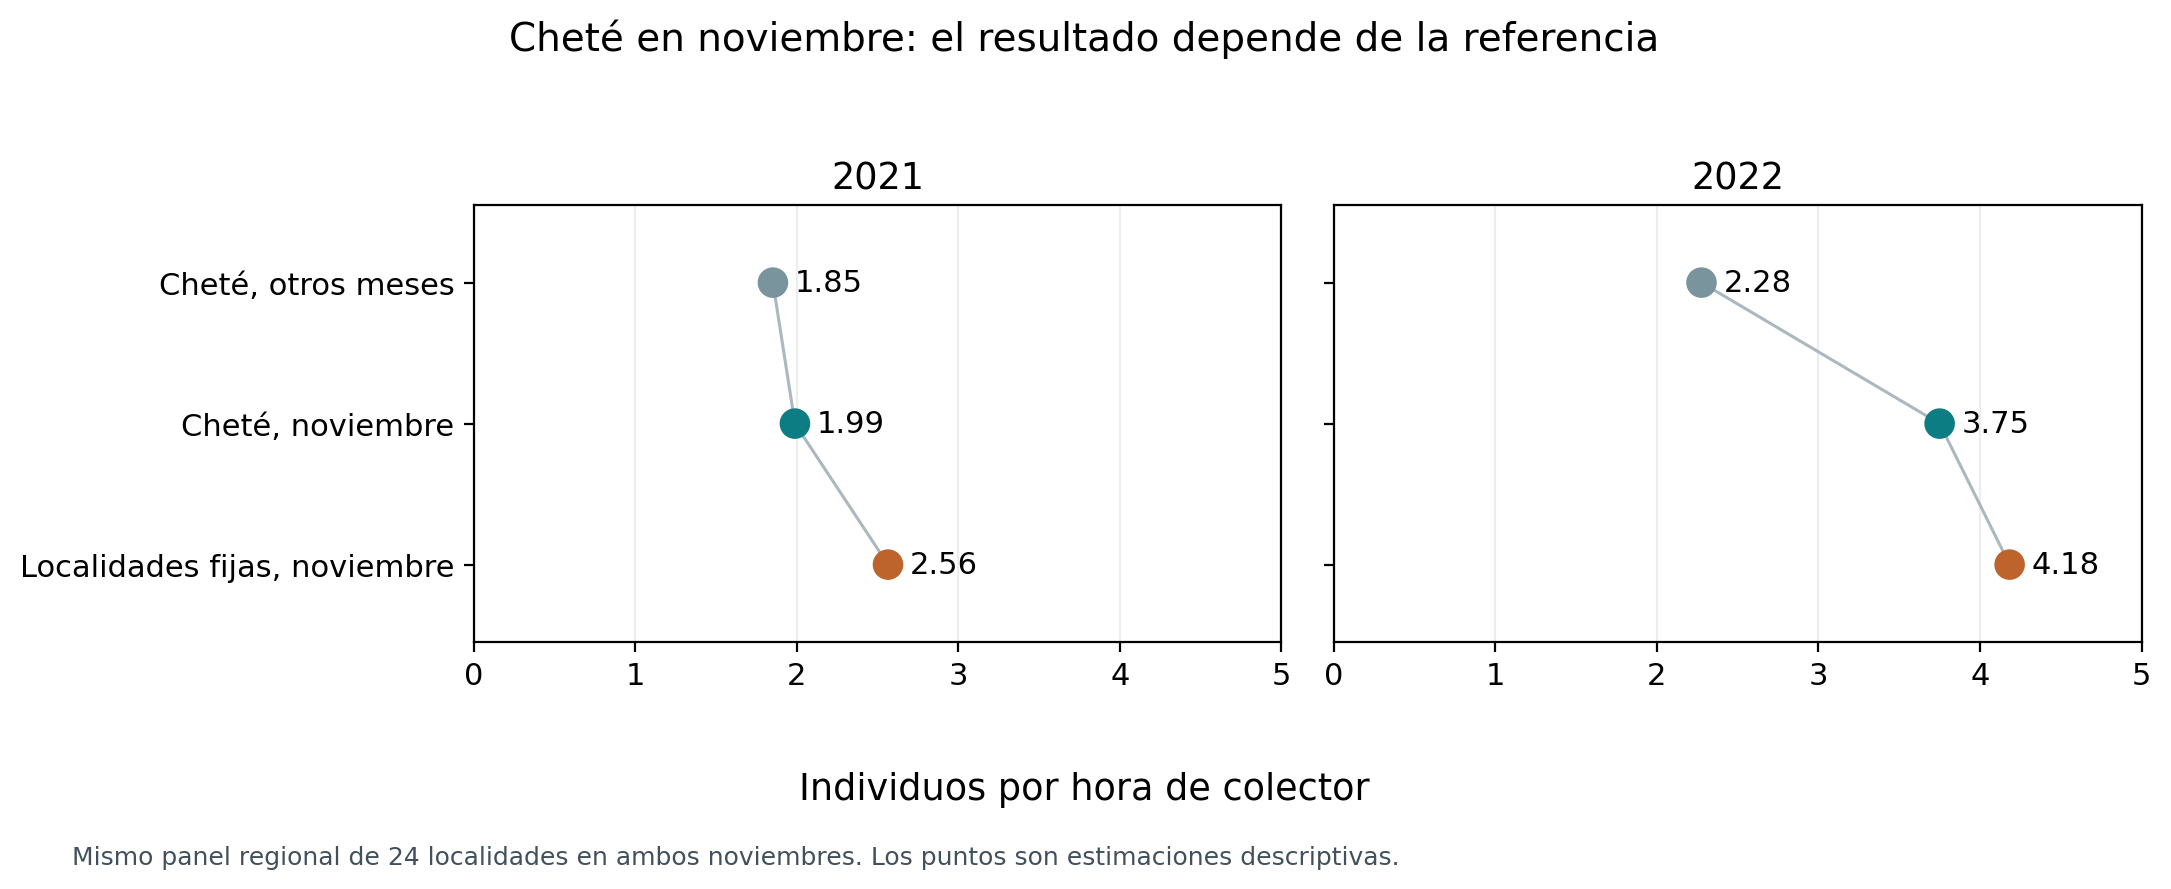

In [24]:
filasEmparejadas = []
aniosNoviembre = sorted(visitasNoviembre.fecha.dt.year.unique())
assert len(aniosNoviembre) == 2
novPorAnio = {}
sitiosPorAnio = {}
for anio in aniosNoviembre:
    seleccion = eventosRegional.loc[
        eventosRegional.fecha.dt.year.eq(anio) & eventosRegional.fecha.dt.month.eq(mesPropuesto)
    ]
    esChete = seleccion.locality.eq("Cheté") & seleccion.county.eq("Timbiquí")
    novPorAnio[anio] = (seleccion.loc[esChete], seleccion.loc[~esChete])
    sitiosPorAnio[anio] = pd.MultiIndex.from_frame(
        seleccion.loc[~esChete, camposSitio].drop_duplicates()
    )
sitiosComunes = sitiosPorAnio[aniosNoviembre[0]].intersection(sitiosPorAnio[aniosNoviembre[1]])
assert not sitiosComunes.empty
print(f"Panel de comparación: {len(sitiosComunes)} localidades externas presentes en ambos noviembres.")

esChete = eventosRegional.locality.eq("Cheté") & eventosRegional.county.eq("Timbiquí")
for anio in aniosNoviembre:
    cheteNov, restoNov = novPorAnio[anio]
    cheteOtros = eventosRegional.loc[
        esChete & eventosRegional.fecha.dt.year.eq(anio) & eventosRegional.fecha.dt.month.ne(mesPropuesto)
    ]
    panelNov = restoNov.loc[pd.MultiIndex.from_frame(restoNov[camposSitio]).isin(sitiosComunes)]
    for nombre, parte in [
        ("Cheté, otros meses", cheteOtros),
        ("Cheté, noviembre", cheteNov),
        ("Resto del estudio, noviembre", restoNov),
        ("Resto de Timbiquí, noviembre", restoNov.loc[restoNov.county.eq("Timbiquí")]),
        ("Localidades fijas, noviembre", panelNov)
    ]:
        filasEmparejadas.append({
            "Año": int(anio), "Ámbito": nombre,
            "Meses observados": parte.fecha.nunique(),
            "Localidades": len(parte[camposSitio].drop_duplicates()),
            "Eventos": len(parte), "Individuos": parte.conteo.sum(),
            "Horas colector": parte.esfuerzo.sum(),
            "Individuos por hora": parte.conteo.sum() / parte.esfuerzo.sum(),
        })
emparejadas = pd.DataFrame(filasEmparejadas)
pareadasAnio = emparejadas.pivot(index="Año", columns="Ámbito", values="Individuos por hora")
novLocal = pareadasAnio["Cheté, noviembre"]
diferenciasNoviembre = pareadasAnio.drop(columns="Cheté, noviembre").rsub(novLocal, axis=0)
diferenciasNoviembre.loc["Promedio con igual peso por año"] = diferenciasNoviembre.mean()
assert (diferenciasNoviembre["Cheté, otros meses"] > 0).all()
assert (diferenciasNoviembre["Resto de Timbiquí, noviembre"] < 0).all()

figNoviembres, ejes = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(11, 4.4))
categorias = ["Cheté, otros meses", "Cheté, noviembre", "Localidades fijas, noviembre"]
colores = ["#79949d", "#0c7d82", "#bd642c"]
for anio, ax in zip(aniosNoviembre, ejes):
    valores = pareadasAnio.loc[anio, categorias].to_numpy(dtype=float)
    ax.plot(valores, [0, 1, 2], "-", color="#abb9bf", lw=1.1, zorder=1)
    ax.scatter(valores, [0, 1, 2], color=colores, s=100, zorder=3)
    for i, valor in enumerate(valores):
        ax.annotate(f"{valor:.2f}", (valor, i), xytext=(8, 0), textcoords="offset points", va="center")
    ax.set(title=str(anio), ylim=(2.55, -.55), xlim=(0, max(5, pareadasAnio[categorias].max().max() + .8)))
    ax.set_yticks([0, 1, 2], categorias)
    ax.grid(axis="x", alpha=.22)
figNoviembres.suptitle("Cheté en noviembre: el resultado depende de la referencia", fontsize=14)
figNoviembres.supxlabel("Individuos por hora de colector", y=.085)
figNoviembres.text(.04, .02, f"Mismo panel regional de {len(sitiosComunes)} localidades en ambos noviembres. "
                   "Los puntos son estimaciones descriptivas.", color="#41505b", fontsize=9)
figNoviembres.tight_layout(rect=(0, .10, 1, .94))
plt.show()

En 2021 y 2022, noviembre en Cheté superó la tasa conjunta de sus otros meses y quedó por debajo del panel externo en esos mismos noviembres. No significa que fuera el mejor mes ni que la lluvia o la minería expliquen la diferencia.

### 9.3. Dónde se midió

Mostramos Colombia y el detalle regional con costa, ríos y municipios. Solo se dibujan eventos con una posición WGS84 sin contradicciones; todos siguen en los totales. El color representa captura por hora, no riesgo de malaria.

In [25]:
camposXY = ["decimalLongitude", "decimalLatitude"]
regional[camposXY] = regional[camposXY].apply(pd.to_numeric, errors="coerce")
coordenadaValida = (
    regional.decimalLatitude.between(-90, 90)
    & regional.decimalLongitude.between(-180, 180)
    & regional.geodeticDatum.eq("WGS84")
)
catalogo = regional.loc[coordenadaValida, claveEvento + camposXY].drop_duplicates()
numeroPosiciones = catalogo.groupby(claveEvento).size().rename("posiciones").reset_index()
estadoMapa = eventosRegional.merge(numeroPosiciones, on=claveEvento, how="left", validate="one_to_one")
estados = np.select([estadoMapa.posiciones.isna(), estadoMapa.posiciones.eq(1)],
                    ["Sin coordenadas válidas", "Una posición válida"],
                    default="Posiciones contradictorias")
estadoMapa["Estado"] = estados
ubicables = estadoMapa.loc[estadoMapa.posiciones.eq(1), claveEvento + ["conteo", "esfuerzo"]]
eventosUbicados = ubicables.merge(catalogo, on=claveEvento, validate="one_to_many")
assert len(eventosUbicados) == len(ubicables)
assert not eventosUbicados.duplicated(claveEvento).any()
mapaRegional = tasasDeGrupos(eventosUbicados, camposXY)
coberturaMapa = eventosUbicados.conteo.sum() / eventosRegional.conteo.sum()
print(f"El mapa incluye {len(mapaRegional)} posiciones y {100 * coberturaMapa:.1f} % de los individuos.")

El mapa incluye 40 posiciones y 92.8 % de los individuos.


Coordenadas dentro del municipio publicado: 40 de 40.


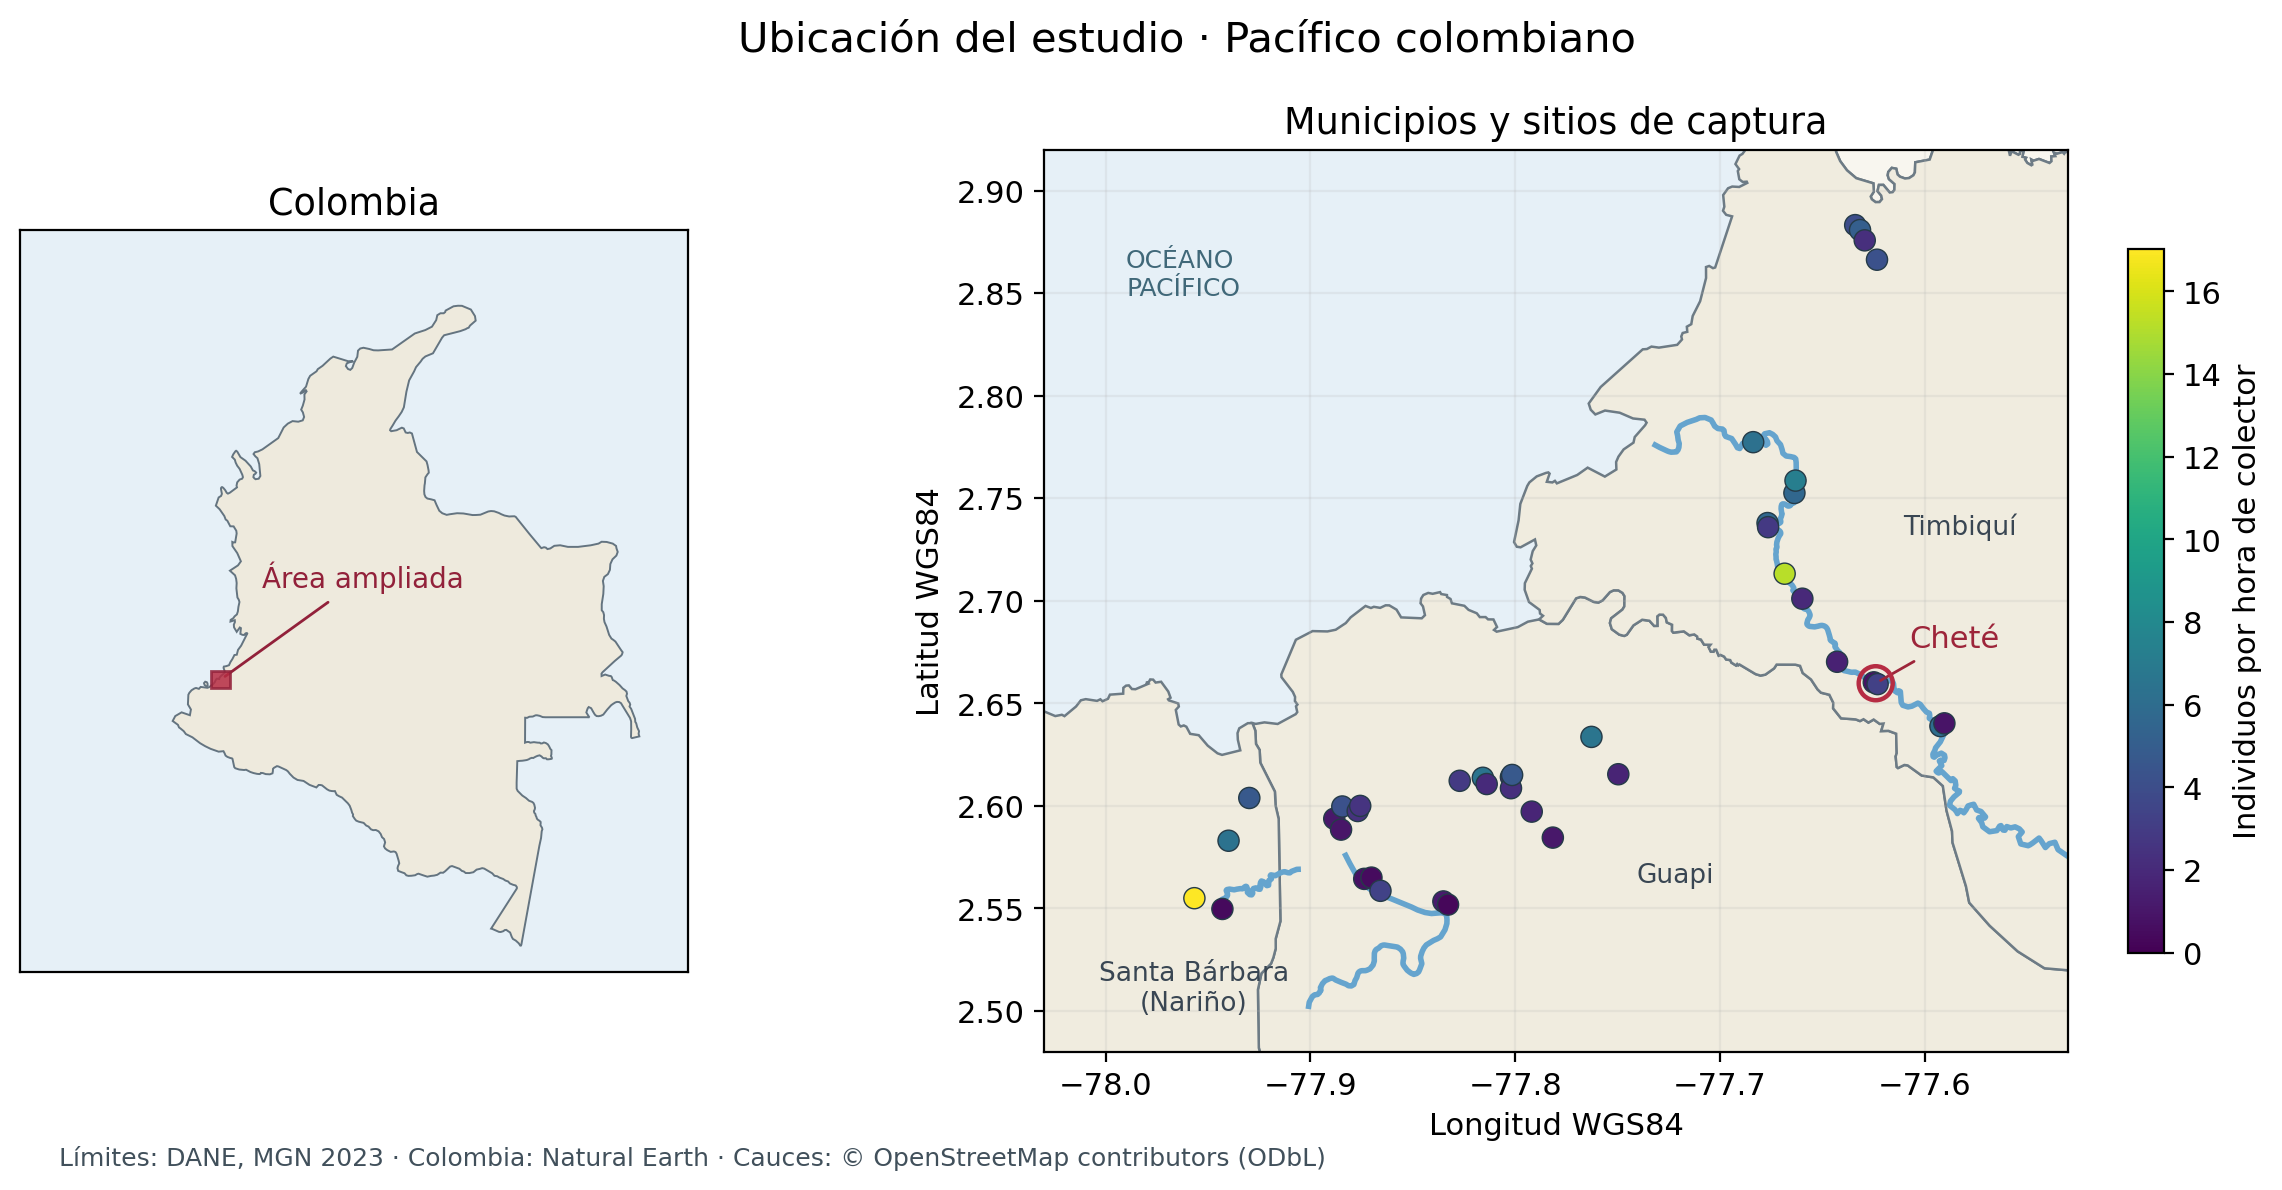

In [26]:
archivoLimites = datos / "limites_pacifico.geojson"
with archivoLimites.open(encoding="utf-8") as fuenteMapa:
    limites = json.load(fuenteMapa)["features"]
colombia = next(f["geometry"] for f in limites if f["properties"]["nivel"] == "pais")
municipios = {
    f["properties"]["nombre"]: f["geometry"]
    for f in limites if f["properties"]["nivel"] == "municipio"
}

def anillosPorPoligono(geometria):
    if geometria["type"] == "Polygon":
        return [geometria["coordinates"]]
    assert geometria["type"] == "MultiPolygon"
    return geometria["coordinates"]

def enPoligonos(posiciones, geometria):
    dentro = np.zeros(len(posiciones), dtype=bool)
    for exterior, *huecos in anillosPorPoligono(geometria):
        enExterior = Trayectoria(exterior).contains_points(posiciones)
        for hueco in huecos:
            enExterior &= ~Trayectoria(hueco).contains_points(posiciones)
        dentro |= enExterior
    return dentro

def pintarPoligonos(eje, geometria, relleno, borde, grosor=.7):
    for anillos in anillosPorPoligono(geometria):
        trazados = [Trayectoria(anillo, closed=True) for anillo in anillos]
        eje.add_patch(PathPatch(Trayectoria.make_compound_path(*trazados), facecolor=relleno,
                                edgecolor=borde, linewidth=grosor, zorder=0))

chequeoMunicipio = eventosUbicados[["county", *camposXY]].drop_duplicates()
coinciden = pd.Series(False, index=chequeoMunicipio.index)
for nombre, grupo in chequeoMunicipio.groupby("county"):
    coinciden.loc[grupo.index] = enPoligonos(
        grupo[camposXY].to_numpy(dtype=float), municipios[nombre.upper()]
    )
print(f"Coordenadas dentro del municipio publicado: {coinciden.sum()} de {len(coinciden)}.")
assert coinciden.all()

encuadre = (-78.03, -77.53, 2.48, 2.92)
figMapaRegional, (axPais, ax) = plt.subplots(
    1, 2, figsize=(12, 6.1), gridspec_kw={"width_ratios": [1, 2.25]}
)
pintarPoligonos(axPais, colombia, "#eeeadd", "#647480")
x0, x1, y0, y1 = encuadre
axPais.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fc="#b62c43",
                           ec="#92213a", alpha=.85, zorder=4))
axPais.annotate("Área ampliada", ((x0 + x1) / 2, (y0 + y1) / 2),
                xytext=(-76.7, 5.1), color="#92213a", fontsize=10,
                arrowprops={"arrowstyle": "-", "color": "#92213a"})
axPais.set(xlim=(-83, -65.6), ylim=(-4.9, 14.4), aspect="equal", title="Colombia")
axPais.set_xticks([])
axPais.set_yticks([])
axPais.set_facecolor("#e6f0f7")

dibujarCauces(ax)
ax.set_facecolor("#e6f0f7")
for nombre, geometria in municipios.items():
    fondo = "#f0ecdf" if nombre in {"TIMBIQUÍ", "GUAPI", "SANTA BÁRBARA"} else "#f8f6ef"
    pintarPoligonos(ax, geometria, fondo, "#6d7b85", .9)
ax.text(-77.99, 2.872, "OCÉANO\nPACÍFICO", color="#406879", fontsize=9, va="top")
for textoMapa, x, y in [
    ("Timbiquí", -77.555, 2.736), ("Guapi", -77.722, 2.566),
    ("Santa Bárbara\n(Nariño)", -77.957, 2.511)
]:
    ax.text(x, y, textoMapa, ha="right" if textoMapa == "Timbiquí" else "center",
            va="center", color="#394653", fontsize=9.5, zorder=2)

puntosMapa = ax.scatter(mapaRegional.decimalLongitude, mapaRegional.decimalLatitude,
                        c=mapaRegional.tasa, cmap="viridis", vmin=0, s=58,
                        edgecolors="#253b48", linewidths=.5, zorder=3)
cx, cy = coordenadas[camposXY].mean()
ax.scatter(cx, cy, marker="o", s=150, facecolors="none", edgecolors="#b62c43",
           lw=1.6, zorder=4)
ax.annotate("Cheté", (cx, cy), xytext=(12, 13), textcoords="offset points",
            color="#9d253a", arrowprops={"arrowstyle": "-", "color": "#9d253a"})
ax.set(xlim=(x0, x1), ylim=(y0, y1), title="Municipios y sitios de captura")
ax.set_aspect(1 / np.cos(np.radians(cy)))
figMapaRegional.suptitle("Ubicación del estudio · Pacífico colombiano", fontsize=15, y=.96)
figMapaRegional.colorbar(puntosMapa, ax=ax, shrink=.78, pad=.04, label="Individuos por hora de colector")
figMapaRegional.text(.03, .021,
                     "Límites: DANE, MGN 2023 · Colombia: Natural Earth · Cauces: © OpenStreetMap contributors (ODbL)",
                     fontsize=9, color="#41505b")
figMapaRegional.tight_layout(rect=(0, .055, 1, .94))
plt.show()

## 10. Qué cambiaríamos

Cambiamos de comparar totales a comparar también el esfuerzo. En la [hoja del plan](../PlanAnalisis_01/plan_analisis.md#hoja-de-campo-de-mosquitos) distinguimos un cero de un fallo y el total recolectado de los *Anopheles* identificados. Dos noches en población y otras dos cerca de una mina confunden sector con fecha. Mediríamos lluvia local fechada para comprobar el supuesto de temporada lluviosa. Para estudiar sesgo de acceso faltarían los sectores previstos, los visitados y las razones de no muestreo.

La IA ayudó a contrastar unidades, depurar la validación y comprobar el calendario. La reflexión y los aportes personales corresponden a cada integrante.

## Apéndice. El modelo de Poisson que se cerró primero

Reproducimos el cierre del modelo anterior a la reserva temporal. Los dos primeros bloques eligieron regularización; los dos siguientes, el margen. Esta es la evaluación original, no otra prueba de los bosques.

In [27]:
def variables(fecha):
    fecha = pd.DatetimeIndex(fecha)
    meses = (fecha.year - 2021) * 12 + fecha.month - 1
    angulo = 2 * np.pi * (fecha.month - 1) / 12
    return np.column_stack([meses / 12, np.sin(angulo), np.cos(angulo)])

def ajustar(entrenamiento, alpha):
    escala = StandardScaler()
    x = escala.fit_transform(variables(entrenamiento.fecha))
    modelo = PoissonRegressor(alpha=alpha, max_iter=2000, tol=1e-8)
    modelo.fit(x, entrenamiento.tasa.to_numpy(dtype=float),
               sample_weight=entrenamiento.esfuerzo.to_numpy(dtype=float))
    return escala, modelo

def predecir(ajuste, fechas):
    escala, modelo = ajuste
    return esfuerzoObjetivo * modelo.predict(escala.transform(variables(fechas)))

def tasaConjunta(tabla):
    return tabla.conteo.sum() / tabla.esfuerzo.sum()

def referencias(entrenamiento, cantidad):
    return {
        "Última visita": np.repeat(entrenamiento.cuatroNoches.iloc[-1], cantidad),
        "Fermi revisada": np.repeat(esfuerzoObjetivo * tasaConjunta(entrenamiento), cantidad)
    }

In [28]:
bloques = [(7, 10), (10, 13), (13, 16), (16, 19)]
for corte, final in bloques:
    assert visitas.iloc[:corte].fin.max() < visitas.iloc[corte:final].inicio.min()

resultadosAlpha = []
for alpha in (0.01, 0.1, 1.0, 10.0):
    errores = []
    for corte, final in bloques[:2]:
        antes, despues = visitas.iloc[:corte], visitas.iloc[corte:final]
        prediccion = predecir(ajustar(antes, alpha), despues.fecha)
        errores.extend(np.abs(despues.cuatroNoches.to_numpy(dtype=float) - prediccion))
    resultadosAlpha.append([alpha, np.mean(errores)])
seleccion = pd.DataFrame(resultadosAlpha, columns=["Regularización", "MAE de selección"])
seleccion = seleccion.sort_values(["MAE de selección", "Regularización"]).reset_index(drop=True)
alphaElegido = float(seleccion.iloc[0]["Regularización"])
print("Regularización elegida:", alphaElegido)

calibracion = []
for corte, final in bloques[2:]:
    antes, despues = visitas.iloc[:corte], visitas.iloc[corte:final]
    pronosticos = referencias(antes, len(despues))
    pronosticos["Poisson"] = predecir(ajustar(antes, alphaElegido), despues.fecha)
    for nombre, pred in pronosticos.items():
        for visita, real, esperado in zip(despues.visita, despues.cuatroNoches, pred):
            calibracion.append([nombre, visita, float(real), float(esperado)])
calibracion = pd.DataFrame(calibracion, columns=["Método", "Visita", "Real", "Predicción"])
calibracion["Error absoluto"] = np.abs(calibracion.Real - calibracion.Predicción)

def margenEmpirico(errores, nivel=0.80):
    errores = np.sort(np.asarray(errores, dtype=float))
    posicion = math.ceil((len(errores) + 1) * nivel)
    assert posicion <= len(errores), "No hay suficientes errores para este nivel."
    return errores[posicion - 1]

margenes = calibracion.groupby("Método")["Error absoluto"].apply(margenEmpirico).to_dict()
ajusteCerrado = ajustar(visitas, alphaElegido)
configuracionCerrada = {
    "archivo": huella, "alpha": alphaElegido, "esfuerzo": esfuerzoObjetivo,
    "variables": ["tiempo", "seno del mes", "coseno del mes"],
    "reserva": sorted(eventosReserva), "margenes": margenes,
    "coeficientes": ajusteCerrado[1].coef_.tolist(),
    "intercepto": float(ajusteCerrado[1].intercept_),
    "mediaEscala": ajusteCerrado[0].mean_.tolist(),
    "escala": ajusteCerrado[0].scale_.tolist()
}
firmaModelo = sha256(json.dumps(configuracionCerrada, sort_keys=True).encode()).hexdigest()
print("Configuración cerrada:", firmaModelo)
print("Reproducción del cierre histórico de Poisson; no es un cierre nuevo.")
fechasReserva = pd.date_range("2023-01-01", periods=3, freq="MS")
pronosticoCerrado = predecir(ajusteCerrado, fechasReserva)
print("Pronósticos cerrados de enero a marzo:", np.round(pronosticoCerrado, 2))

Regularización elegida: 10.0
Configuración cerrada: ab3f65bc26c4696fc255c62a8aa83c18a1797b9839da3ffd229437be5b02de3c
Reproducción del cierre histórico de Poisson; no es un cierre nuevo.
Pronósticos cerrados de enero a marzo: [213.34 214.1  215.81]


In [29]:
predicciones = referencias(visitas, len(prueba))
predicciones["Poisson"] = pronosticoCerrado
evaluacion = []
for nombre, pred in predicciones.items():
    real = prueba.cuatroNoches.to_numpy(dtype=float)
    bajo = np.maximum(0, pred - margenes[nombre])
    alto = pred + margenes[nombre]
    cobertura = (real >= bajo) & (real <= alto)
    evaluacion.append({
        "Método": nombre,
        "MAE": mean_absolute_error(real, pred),
        "RMSE": np.sqrt(mean_squared_error(real, pred)),
        "Sesgo": np.mean(pred - real),
        "Cobertura": cobertura.mean(),
        "Ancho medio": np.mean(alto - bajo)
    })
metricas = pd.DataFrame(evaluacion).set_index("Método")
display(metricas)

,MAE,RMSE,Sesgo,Cobertura,Ancho medio
Método,,,,,
Última visita,44.83,54.11,-21.83,1.0,326.29
Fermi revisada,64.04,80.74,63.79,1.0,309.81
Poisson,68.08,84.76,68.08,1.0,298.54


## 11. Resultados reproducibles y fuentes

La [presentación](Presentacion.pdf) acompaña el análisis y es independiente del notebook. Para reproducir los cálculos se usan los archivos de `Datos/` y las versiones de las bibliotecas que imprime la primera celda.

Datos: [Ahumada y colaboradores, INS, v1.0, 2023](https://doi.org/10.15472/kftrcn), CC BY-NC 4.0. Cartografía: [DANE, MGN 2023](https://geoportal.dane.gov.co/descargas/mgn_2023/MGN2023_CatalogoDeObjetos.pdf), [Natural Earth](https://www.naturalearthdata.com/about/terms-of-use/) y [© OpenStreetMap contributors](https://www.openstreetmap.org/copyright), ODbL. Imagen anotada: aportada por el equipo. Modelos e importancia: [scikit-learn](https://scikit-learn.org/stable/modules/permutation_importance.html).